# Lab 4 - Sieci splotowe (CNN) i transfer learning

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne)
**Prowadząca:** dr inż. Natalia Piórkowska
**Środowisko:** Google Colab, GPU T4, TensorFlow / Keras 3

## Cel zajęć

W L3 obrazy Fashion-MNIST "spłaszczaliśmy" do wektora 784 liczb - MLP nie wiedział, które piksele są sąsiadami. Dziś poznasz **sieci splotowe (CNN)**, które wykorzystują strukturę przestrzenną obrazu, oraz **transfer learning** - korzystanie z sieci wytrenowanej na milionach obrazów (ImageNet). Po zajęciach będziesz umieć:

1. policzyć splot "ręcznie" w NumPy i zrozumieć, co robi filtr (filtry Sobela - wykrywanie krawędzi),
2. wyznaczyć wymiary wyjścia i liczbę parametrów warstwy `Conv2D`,
3. zbudować CNN w Keras i porównać ją z MLP z L3 (parametry vs dokładność),
4. trenować CNN na CIFAR-10 z BatchNorm, Dropout i **augmentacją danych** warstwami Keras,
5. zbudować **blok residualny** w Functional API i użyć `GlobalAveragePooling2D`,
6. wizualizować **filtry** i **mapy cech**,
7. zastosować **transfer learning** z MobileNetV2 (zamrożona baza + nowa głowa, potem **fine-tuning**),
8. ocenić model **macierzą pomyłek**.

## Efekty uczenia (z karty przedmiotu)

- **UGŁ_W01** - zna modele DL (CNN, ResNet, MobileNet) i metody ich uczenia.
- **UGŁ_W02** - zna zaawansowane metody i narzędzia DL (transfer learning, augmentacja, `keras.applications`).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "CNN przy mniejszej liczbie parametrów osiągnie lepszą dokładność niż MLP").
- **UGŁ_U02** - proponuje usprawnienia w oparciu o istniejące biblioteki (gotowe modele pretrenowane).
- **UGŁ_K01** - rozumie potrzebę korzystania z najnowszej wiedzy (ewolucja architektur: LeNet -> VGG -> ResNet -> MobileNet).

## Powiązanie z wykładem

- **W2** - splot (filtr, stride, padding, wzór na wymiar wyjścia, współdzielenie wag, pole recepcyjne), pooling, Flatten, BatchNorm, Dropout, połączenia residualne.
- **W3** - regularyzacja, augmentacja, callbacki (z L3).
- **W4** - CNN (LeNet, VGG, ResNet), transfer learning i fine-tuning, macierz pomyłek, Grad-CAM (zadanie dodatkowe). **Główne wykłady do tych zajęć: W2 i W4.**

## Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | Wstęp, przygotowanie środowiska (sekcja 0) |
| 10-35 min | 1. Splot ręcznie: NumPy, filtry Sobela, wymiary i parametry (zad. 1.1, 1.2) |
| 35-60 min | 2. CNN na Fashion-MNIST vs MLP z L3 (zad. 2.1) |
| 60-90 min | 3. CIFAR-10: CNN z BatchNorm, Dropout i augmentacją (zad. 3.1) |
| 90-100 min | **Przerwa (10 min)** |
| 100-120 min | 4. Blok residualny i GlobalAveragePooling (zad. 4.1) |
| 120-135 min | 5. Wizualizacja filtrów i map cech (zad. 5.1) |
| 135-170 min | 6. Transfer learning MobileNetV2: ekstrakcja cech, fine-tuning, macierz pomyłek (zad. 6.1, 6.2, 6.3) |
| 170-180 min | Pytania kontrolne, podsumowanie, informacje do sprawozdania |

## Wymagania wstępne

- L3: `compile` / `fit` / `evaluate`, krzywe uczenia, callbacki, Dropout, BatchNorm.
- Funkcja `rysuj_historie` z L3 (zdefiniujemy ją ponownie).
- Intuicja: obraz kolorowy to tensor o kształcie (wysokość, szerokość, kanały).

## 0. Przygotowanie środowiska

### Włączenie GPU w Colab
**Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU -> Zapisz.** Zrób to przed uruchomieniem pierwszej komórki. Sieci splotowe na CPU trenują się kilkadziesiąt razy wolniej - na tych zajęciach GPU jest naprawdę potrzebne.

### Tryb szybki
`SZYBKI_TRYB = True` oznacza: mniej obrazów (np. 2000 zamiast 50 000), 1-2 epoki, mały podzbiór do transfer learningu. Wyniki będą słabe, ale całość przejdzie w kilka minut nawet na CPU. **Przełącz na `True`, jeśli pracujesz bez GPU** lub chcesz najpierw sprawdzić, czy kod działa.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cisza dla logow TensorFlow (INFO/WARNING z warstwy C++), nie zmienia dzialania
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
_devnull = os.open(os.devnull, os.O_WRONLY)
_stderr_backup = os.dup(2)
os.dup2(_devnull, 2)
try:
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")       # logi Pythona TF tylko dla bledow
    tf.config.list_physical_devices("GPU")  # pierwsze wywolanie zuzywa ostrzezenie o GPU
finally:
    import sys
    sys.stderr.flush()
    os.dup2(_stderr_backup, 2)
    os.close(_devnull); os.close(_stderr_backup)

import keras
from keras import layers
from sklearn.metrics import confusion_matrix, classification_report

# Tryb szybki: True = mniej danych i epok (praca na CPU / szybki test kodu)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jezeli pracujesz bez GPU

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("SZYBKI_TRYB =", SZYBKI_TRYB)

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "brak - obliczenia na CPU, rozwaz SZYBKI_TRYB = True")

SEED = 42
keras.utils.set_random_seed(SEED)   # seed dla Pythona, NumPy i TF jednoczesnie
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0 | Keras: 3.12.4
SZYBKI_TRYB = False
GPU: brak - obliczenia na CPU, rozwaz SZYBKI_TRYB = True


In [2]:
def rysuj_historie(historia, metryka="accuracy", tytul=""):
    # Rysuje stratę i metrykę (train vs walidacja) z obiektu History lub słownika
    h = historia.history if hasattr(historia, "history") else historia
    ep = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(["loss", metryka]):
        ax[i].plot(ep, h[m], "o-", label="train")
        if "val_" + m in h:
            ax[i].plot(ep, h["val_" + m], "s-", label="walidacja")
        ax[i].set_xlabel("epoka"); ax[i].set_ylabel(m); ax[i].set_title(f"{tytul} - {m}")
        ax[i].legend(); ax[i].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def rysuj_macierz_pomylek(y_true, y_pred, nazwy, tytul):
    # Macierz pomyłek z liczbami w komórkach
    cm = confusion_matrix(y_true, y_pred, labels=range(len(nazwy)))
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(nazwy))); ax.set_xticklabels(nazwy, rotation=60, ha="right")
    ax.set_yticks(range(len(nazwy))); ax.set_yticklabels(nazwy)
    for i in range(len(nazwy)):
        for j in range(len(nazwy)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa"); ax.set_title(tytul)
    plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()
    return cm

## 1. Splot "ręcznie"

### Definicja (W2)
Dla obrazu $X$ (jeden kanał) i filtra (jądra) $K$ o rozmiarze $k \times k$ wyjście warstwy splotowej to

$$Y[i, j] = \sum_{u=0}^{k-1} \sum_{v=0}^{k-1} X[i \cdot s + u,\; j \cdot s + v] \cdot K[u, v] + b,$$

gdzie $s$ to **krok (stride)**. Filtr "przesuwa się" po obrazie i w każdym położeniu liczy iloczyn skalarny z fragmentem obrazu.

> Uwaga terminologiczna: w głębokim uczeniu "splot" to formalnie **korelacja wzajemna** (filtr nie jest odwracany). Dla uczonych filtrów nie ma to znaczenia - sieć nauczy się filtra "odwróconego".

### Wymiar wyjścia
Dla wejścia o rozmiarze $n$, filtra $k$, paddingu $p$ (dopisanie $p$ zer z każdej strony) i kroku $s$:

$$n_{out} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1.$$

W Keras `padding="valid"` oznacza $p = 0$, a `padding="same"` dobiera padding tak, by $n_{out} = \lceil n / s \rceil$ (przy $s=1$ wymiar się nie zmienia).

### Dlaczego splot, a nie warstwa gęsta?
- **Współdzielenie wag:** ten sam filtr stosujemy w każdym miejscu obrazu - liczba parametrów nie zależy od rozmiaru obrazu.
- **Lokalność:** każdy neuron "patrzy" tylko na mały fragment (pole recepcyjne); głębsze warstwy widzą coraz większe obszary.
- **Równoważność względem przesunięcia:** przesunięty obiekt daje przesuniętą mapę cech.

In [3]:
# Wczytujemy Fashion-MNIST - użyjemy go w sekcjach 1 i 2
(xf_tr_full, yf_tr_full), (xf_test, yf_test) = keras.datasets.fashion_mnist.load_data()
if SZYBKI_TRYB:
    xf_tr_full, yf_tr_full = xf_tr_full[:2000], yf_tr_full[:2000]
    xf_test, yf_test = xf_test[:500], yf_test[:500]
xf_tr_full = xf_tr_full.astype("float32") / 255.0
xf_test = xf_test.astype("float32") / 255.0
NAZWY_FASHION = ["T-shirt/top", "Spodnie", "Sweter", "Sukienka", "Płaszcz",
                 "Sandał", "Koszula", "Sneaker", "Torba", "Botek"]

# Prosty obraz syntetyczny: jasny kwadrat na ciemnym tle - krawędzie są oczywiste
kwadrat = np.zeros((28, 28), dtype="float32")
kwadrat[8:20, 8:20] = 1.0
obraz_fashion = xf_test[0]       # pierwszy obraz testowy
print("klasa obrazu testowego:", NAZWY_FASHION[yf_test[0]])

klasa obrazu testowego: Botek


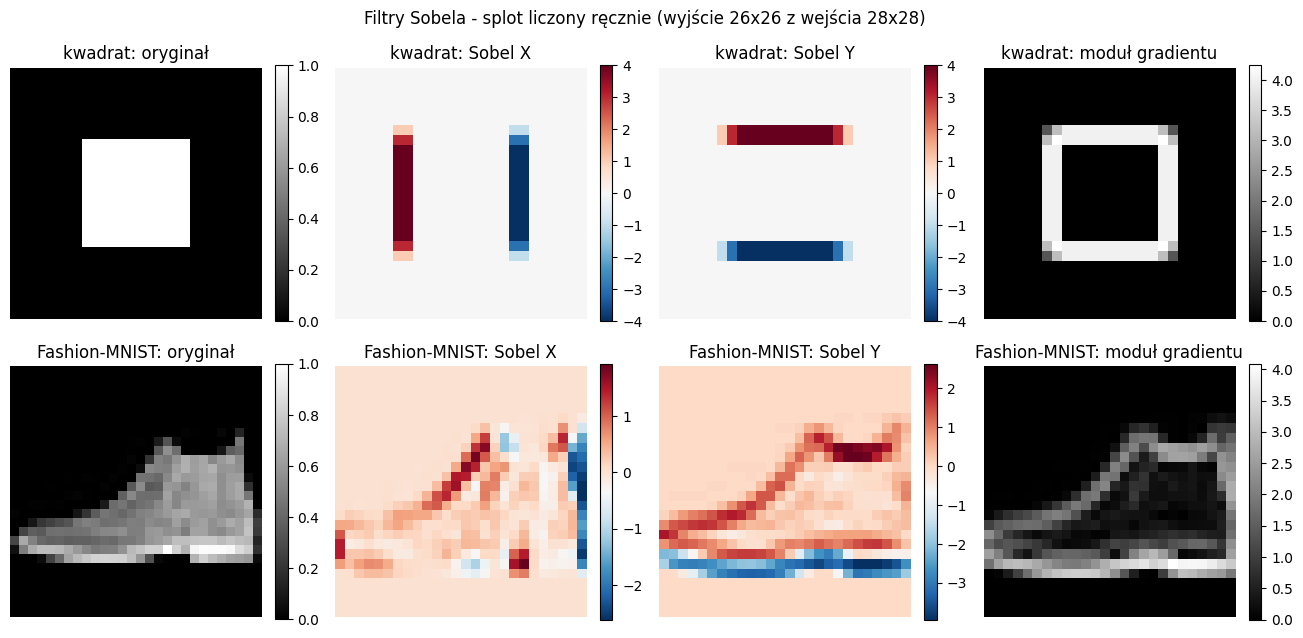

In [4]:
def splot2d_prosty(obraz, filtr):
    # Splot (korelacja) bez paddingu, stride = 1: pętla po pozycjach wyjścia
    k = filtr.shape[0]
    h_out = obraz.shape[0] - k + 1          # wzór: n - k + 1
    w_out = obraz.shape[1] - k + 1
    wyjscie = np.zeros((h_out, w_out), dtype="float32")
    for i in range(h_out):
        for j in range(w_out):
            fragment = obraz[i:i + k, j:j + k]          # okno k x k
            wyjscie[i, j] = np.sum(fragment * filtr)    # iloczyn skalarny okna i filtra
    return wyjscie

# Filtry Sobela: przybliżenie pochodnej obrazu w kierunku x (krawędzie pionowe) i y (poziome)
SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype="float32")
SOBEL_Y = SOBEL_X.T

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for r, (nazwa, img) in enumerate([("kwadrat", kwadrat), ("Fashion-MNIST", obraz_fashion)]):
    gx = splot2d_prosty(img, SOBEL_X)
    gy = splot2d_prosty(img, SOBEL_Y)
    modul = np.sqrt(gx ** 2 + gy ** 2)      # moduł gradientu = "siła" krawędzi
    for c, (t, im) in enumerate([("oryginał", img), ("Sobel X", gx), ("Sobel Y", gy), ("moduł gradientu", modul)]):
        h = axes[r, c].imshow(im, cmap="gray" if c in (0, 3) else "RdBu_r")
        axes[r, c].set_title(f"{nazwa}: {t}"); axes[r, c].axis("off")
        plt.colorbar(h, ax=axes[r, c], fraction=0.046)
plt.suptitle("Filtry Sobela - splot liczony ręcznie (wyjście 26x26 z wejścia 28x28)")
plt.tight_layout(); plt.show()

**Co obserwować:** Sobel X reaguje na krawędzie **pionowe** (zmiana jasności w poziomie) - dodatnio przy przejściu ciemne -> jasne, ujemnie przy jasne -> ciemne. Sobel Y analogicznie dla krawędzi poziomych. Moduł gradientu podświetla kontury niezależnie od kierunku. Pierwsze warstwy CNN uczą się filtrów bardzo podobnych do takich detektorów krawędzi - zobaczymy to w sekcji 5.

### Zadanie 1.1 - Splot z krokiem i paddingiem

Napisz funkcję `splot2d(obraz, filtr, stride=1, padding=0)`, która:
1. dopełnia obraz zerami o szerokości `padding` z każdej strony (`np.pad`),
2. wyznacza wymiar wyjścia ze wzoru $\lfloor (n + 2p - k)/s \rfloor + 1$,
3. liczy splot z zadanym krokiem.

Następnie zweryfikuj ją z `tf.nn.conv2d` dla obrazu `obraz_fashion`, filtra `SOBEL_X`, `stride=2`, `padding=1`. Maksymalna różnica bezwzględna powinna być < 1e-5.

**Kryteria sukcesu:** wyjście ma kształt (14, 14); różnica z TensorFlow < 1e-5.

**Wskazówki:** `tf.nn.conv2d` oczekuje wejścia o kształcie `(batch, H, W, kanały_we)` i filtra `(kH, kW, kanały_we, kanały_wy)`; jawny padding podaje się jako `padding=[[0, 0], [p, p], [p, p], [0, 0]]`, krok jako `strides=s`. Okno w pozycji (i, j) zaczyna się w wierszu `i * stride`.

ksztalt wyjscia NumPy: (14, 14), TensorFlow: (14, 14) (wzor: 14x14)
maksymalna roznica bezwzgledna: 1.192e-07
OK: splot2d zgadza sie z tf.nn.conv2d


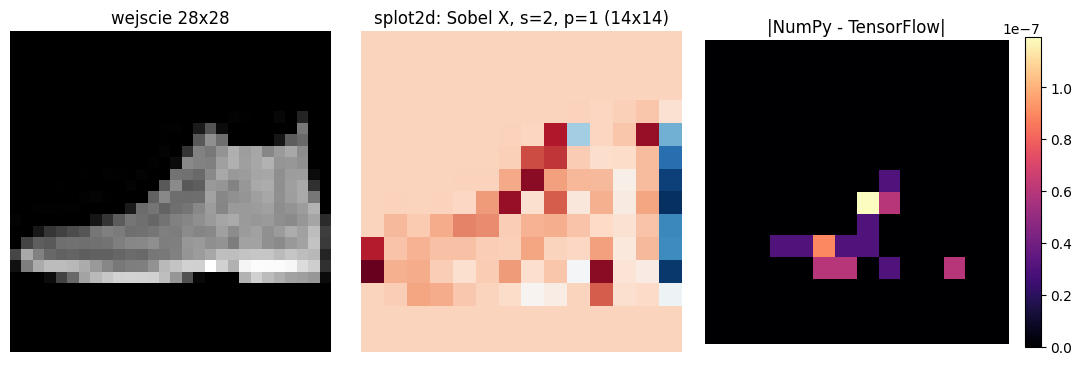

In [5]:
def splot2d(obraz, filtr, stride=1, padding=0):
    # Splot (korelacja) z krokiem i zerowym paddingiem - bez wyrazu wolnego
    if padding > 0:
        obraz = np.pad(obraz, ((padding, padding), (padding, padding)), mode="constant")
    k = filtr.shape[0]
    h_out = (obraz.shape[0] - k) // stride + 1      # floor((n + 2p - k) / s) + 1
    w_out = (obraz.shape[1] - k) // stride + 1
    wyjscie = np.zeros((h_out, w_out), dtype="float32")
    for i in range(h_out):
        for j in range(w_out):
            okno = obraz[i * stride:i * stride + k, j * stride:j * stride + k]
            wyjscie[i, j] = np.sum(okno * filtr)
    return wyjscie


# Weryfikacja z tf.nn.conv2d: obraz_fashion, Sobel X, stride = 2, padding = 1
STRIDE, PADDING = 2, 1
y_numpy = splot2d(obraz_fashion, SOBEL_X, stride=STRIDE, padding=PADDING)

# tf.nn.conv2d oczekuje (batch, H, W, C) oraz filtra (kH, kW, C_in, C_out)
y_tensorflow = tf.nn.conv2d(
    obraz_fashion[None, :, :, None],
    SOBEL_X[:, :, None, None],
    strides=[1, STRIDE, STRIDE, 1],
    padding=[[0, 0], [PADDING, PADDING], [PADDING, PADDING], [0, 0]],
).numpy()[0, :, :, 0]

n_out = (obraz_fashion.shape[0] + 2 * PADDING - SOBEL_X.shape[0]) // STRIDE + 1
roznica = float(np.abs(y_numpy - y_tensorflow).max())
print(f"ksztalt wyjscia NumPy: {y_numpy.shape}, TensorFlow: {y_tensorflow.shape} (wzor: {n_out}x{n_out})")
print(f"maksymalna roznica bezwzgledna: {roznica:.3e}")
assert y_numpy.shape == (14, 14) == y_tensorflow.shape, "zly ksztalt wyjscia"
assert roznica < 1e-5, "zgodnosc z tf.nn.conv2d nie zostala spelniona"
print("OK: splot2d zgadza sie z tf.nn.conv2d")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
ax[0].imshow(obraz_fashion, cmap="gray"); ax[0].set_title("wejscie 28x28"); ax[0].axis("off")
ax[1].imshow(y_numpy, cmap="RdBu_r"); ax[1].set_title("splot2d: Sobel X, s=2, p=1 (14x14)"); ax[1].axis("off")
h = ax[2].imshow(np.abs(y_numpy - y_tensorflow), cmap="magma")
ax[2].set_title("|NumPy - TensorFlow|"); ax[2].axis("off")
plt.colorbar(h, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

### Liczba parametrów warstwy `Conv2D` (W2)

Filtr w warstwie splotowej obejmuje **wszystkie kanały wejścia**. Warstwa `Conv2D(filters=F, kernel_size=k)` na wejściu z $C_{in}$ kanałami ma

$$\#\text{param} = k \cdot k \cdot C_{in} \cdot F + F.$$

Przykład: `Conv2D(32, 3)` na obrazie RGB: $3\cdot3\cdot3\cdot32 + 32 = 896$ - niezależnie od tego, czy obraz ma 32x32, czy 1000x1000 pikseli. Porównaj: warstwa `Dense(32)` na spłaszczonym obrazie 32x32x3 miałaby $3072 \cdot 32 + 32 = 98\,336$ parametrów.

`MaxPooling2D(2)` wybiera maksimum z każdego okna 2x2 (krok 2) - zmniejsza wymiar dwukrotnie i **nie ma parametrów**.

In [6]:
# Demonstracja: Keras liczy dokładnie według wzoru
demo = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),   # 32x32x32, 3*3*3*32+32 = 896
    layers.MaxPooling2D(2),                                    # 16x16x32, 0 parametrów
])
demo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

**Pole recepcyjne (W2):** jeden piksel wyjścia pierwszej warstwy 3x3 "widzi" 3x3 piksele wejścia. Po dwóch splotach 3x3 (stride 1) - 5x5, po trzech - 7x7; pooling 2x2 podwaja tempo wzrostu. Dlatego głębokie warstwy mogą wykrywać duże obiekty, choć każdy filtr jest mały. Stos dwóch splotów 3x3 ma to samo pole recepcyjne co jeden splot 5x5, ale mniej parametrów ($2\cdot 9 C^2$ vs $25 C^2$) i dodatkową nieliniowość - to główna idea architektury VGG (W4).

### Zadanie 1.2 - Wymiary i parametry na papierze

Dla sieci:
```
Input(32, 32, 3)
Conv2D(16, kernel_size=5, strides=1, padding="valid")
MaxPooling2D(2)
Conv2D(32, kernel_size=3, strides=2, padding="same")
Flatten()
Dense(10)
```
1. Uzupełnij funkcję `wymiar_wyjscia(n, k, s, p)` (wzór powyżej).
2. **Ręcznie** (w kodzie, ale bez budowania modelu) wyznacz kształt wyjścia i liczbę parametrów każdej warstwy - zapisz je w liście `moje` krotek `(nazwa, kształt, parametry)`.
3. Zbuduj ten model w Keras i porównaj z `model.summary()` (lub z `layer.output.shape` i `layer.count_params()` w pętli).

**Kryteria sukcesu:** wszystkie kształty i liczby parametrów zgadzają się z Keras.

**Wskazówka:** dla `padding="same"` przy kroku $s$ wymiar wyjścia to $\lceil n/s \rceil$.

In [7]:
def wymiar_wyjscia(n, k, s=1, p=0):
    # floor((n + 2p - k) / s) + 1
    return (n + 2 * p - k) // s + 1


# 1. Reczne wyliczenia - tylko wzory, bez budowania modelu
n1 = wymiar_wyjscia(32, 5, s=1, p=0)      # Conv2D(16, 5, valid)  -> 28
n2 = wymiar_wyjscia(n1, 2, s=2, p=0)      # MaxPooling2D(2)       -> 14
n3 = -(-n2 // 2)                          # padding="same", s=2   -> ceil(n/s) = 7
plaskie = n3 * n3 * 32                    # Flatten               -> 1568

moje = [
    ("Conv2D(16, 5, valid)", (n1, n1, 16), 5 * 5 * 3 * 16 + 16),
    ("MaxPooling2D(2)", (n2, n2, 16), 0),
    ("Conv2D(32, 3, same, s=2)", (n3, n3, 32), 3 * 3 * 16 * 32 + 32),
    ("Flatten", (plaskie,), 0),
    ("Dense(10)", (10,), plaskie * 10 + 10),
]
for nazwa, ksztalt, par in moje:
    print(f"{nazwa:26s} ksztalt={str(ksztalt):16s} parametry={par:,}")
print(f"{'RAZEM (recznie)':26s} {'':16s} parametry={sum(p for _, _, p in moje):,}")

# 2. Ten sam model w Keras
model_12 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 5, strides=1, padding="valid"),   # 28x28x16
    layers.MaxPooling2D(2),                             # 14x14x16
    layers.Conv2D(32, 3, strides=2, padding="same"),    # 7x7x32
    layers.Flatten(),                                   # 1568
    layers.Dense(10),                                   # 10
], name="zadanie_1_2")

# 3. Porownanie warstwa po warstwie: ksztalt wyjscia i liczba parametrow
zgodne = True
for (nazwa, ksztalt, par), warstwa in zip(moje, model_12.layers):
    k_keras = tuple(int(d) for d in warstwa.output.shape[1:])
    ok = (k_keras == ksztalt) and (warstwa.count_params() == par)
    zgodne = zgodne and ok
    print(f"{warstwa.name:20s} Keras: ksztalt={str(k_keras):16s} "
          f"parametry={warstwa.count_params():>6,}  zgodne={ok}")
assert zgodne, "reczne wyliczenia nie zgadzaja sie z Keras"
print("OK: wszystkie ksztalty i liczby parametrow zgodne z Keras")
model_12.summary()

Conv2D(16, 5, valid)       ksztalt=(28, 28, 16)     parametry=1,216
MaxPooling2D(2)            ksztalt=(14, 14, 16)     parametry=0
Conv2D(32, 3, same, s=2)   ksztalt=(7, 7, 32)       parametry=4,640
Flatten                    ksztalt=(1568,)          parametry=0
Dense(10)                  ksztalt=(10,)            parametry=15,690
RAZEM (recznie)                             parametry=21,546
conv2d_1             Keras: ksztalt=(28, 28, 16)     parametry= 1,216  zgodne=True
max_pooling2d_1      Keras: ksztalt=(14, 14, 16)     parametry=     0  zgodne=True
conv2d_2             Keras: ksztalt=(7, 7, 32)       parametry= 4,640  zgodne=True
flatten              Keras: ksztalt=(1568,)          parametry=     0  zgodne=True
dense                Keras: ksztalt=(10,)            parametry=15,690  zgodne=True
OK: wszystkie ksztalty i liczby parametrow zgodne z Keras


Model: "zadanie_1_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 28, 28, 16)          │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 7, 7, 32)            │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1568)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          15,690 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,546 (84.16 KB)

 Trainable params: 21,546 (84.16 KB)

 Non-trainable params: 0 (0.00 B)

## 2. CNN na Fashion-MNIST vs MLP z L3

Typowa "klasyczna" CNN (styl LeNet / VGG, W4) to naprzemienne bloki **splot + aktywacja + pooling**, które stopniowo zmniejszają rozdzielczość i zwiększają liczbę kanałów (cech), a na końcu klasyfikator gęsty.

Warstwy `Conv2D` oczekują wejścia z osią kanałów: obraz Fashion-MNIST 28x28 trzeba przekształcić do 28x28x1.

Najpierw odtwórzmy **baseline MLP z L3**, żeby mieć uczciwe porównanie (te same dane, te same epoki).

In [8]:
# Dodajemy oś kanałów: (n, 28, 28) -> (n, 28, 28, 1)
xf_tr4 = xf_tr_full[..., None]
xf_te4 = xf_test[..., None]
n_val_f = len(xf_tr4) // 6
xf_train, yf_train = xf_tr4[:-n_val_f], yf_tr_full[:-n_val_f]
xf_val, yf_val = xf_tr4[-n_val_f:], yf_tr_full[-n_val_f:]
print("train:", xf_train.shape, "val:", xf_val.shape, "test:", xf_te4.shape)

EPOKI_F = 2 if SZYBKI_TRYB else 12

# Baseline z L3: MLP 256-128
keras.utils.set_random_seed(SEED)
mlp_f = keras.Sequential([keras.Input(shape=(28, 28, 1)), layers.Flatten(),
                          layers.Dense(256, activation="relu"), layers.Dense(128, activation="relu"),
                          layers.Dense(10, activation="softmax")], name="mlp_L3")
mlp_f.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_mlp_f = mlp_f.fit(xf_train, yf_train, epochs=EPOKI_F, batch_size=128,
                       validation_data=(xf_val, yf_val), verbose=0)
czas_mlp = time.time() - t0
acc_mlp_f = mlp_f.evaluate(xf_te4, yf_test, verbose=0)[1]
print(f"MLP: parametry = {mlp_f.count_params():,}, test acc = {acc_mlp_f:.4f}, czas = {czas_mlp:.1f} s")

train: (50000, 28, 28, 1) val: (10000, 28, 28, 1) test: (10000, 28, 28, 1)
MLP: parametry = 235,146, test acc = 0.8713, czas = 21.5 s


### Zadanie 2.1 - Pierwsza CNN

Zbuduj `cnn_f` (Sequential):
```
Input(28, 28, 1)
Conv2D(32, 3, padding="same", activation="relu") -> MaxPooling2D(2)      # 14x14x32
Conv2D(64, 3, padding="same", activation="relu") -> MaxPooling2D(2)      # 7x7x64
Flatten -> Dense(128, relu) -> Dropout(0.3) -> Dense(10, softmax)
```
1. Skompiluj (Adam, `sparse_categorical_crossentropy`, accuracy), wytrenuj `EPOKI_F` epok (batch 128) z walidacją i zmierz czas treningu.
2. Narysuj krzywe uczenia.
3. Zbuduj tabelę porównawczą MLP vs CNN: liczba parametrów, dokładność testowa, czas treningu.
4. **Hipoteza (UGŁ_U01):** zanim uruchomisz, zapisz w markdown, czy spodziewasz się, że CNN będzie lepsza, i czy będzie miała więcej, czy mniej parametrów. Zweryfikuj po treningu.

**Kryteria sukcesu (pełny tryb):** test accuracy CNN >= 0.91 (MLP ok. 0.88).

*Hipoteza (przed uruchomieniem):* Spodziewam się, że CNN będzie **dokładniejsza** od MLP 256-128
(test accuracy ok. 0.91-0.93 przy ok. 0.88 dla MLP), bo splot korzysta z lokalności i współdzielenia wag -
uczy się filtrów na krawędzie i tekstury, zamiast traktować 784 pikseli jako niezależne cechy.

Jednocześnie przewiduję, że CNN będzie miała **więcej parametrów**, a nie mniej. Sploty są tanie:
`3x3x1x32 + 32 = 320` i `3x3x32x64 + 64 = 18 496` parametrów (razem 18 816), ale mapa `7x7x64`
po `Flatten` daje wektor 3136 liczb, a `Dense(128)` dokłada `3136x128 + 128 = 401 536` parametrów.
Razem ok. **421 642** parametry wobec **235 146** dla MLP 256-128. Czas treningu CNN będzie wyraźnie
dłuższy (więcej operacji mimo mniejszej liczby parametrów w warstwach splotowych).

Epoch 1/12
391/391 - 16s - 42ms/step - accuracy: 0.8031 - loss: 0.5489 - val_accuracy: 0.8771 - val_loss: 0.3476
Epoch 2/12
391/391 - 15s - 38ms/step - accuracy: 0.8774 - loss: 0.3447 - val_accuracy: 0.8928 - val_loss: 0.2997
Epoch 3/12
391/391 - 14s - 37ms/step - accuracy: 0.8921 - loss: 0.2987 - val_accuracy: 0.9044 - val_loss: 0.2683
Epoch 4/12
391/391 - 14s - 36ms/step - accuracy: 0.9049 - loss: 0.2650 - val_accuracy: 0.9046 - val_loss: 0.2581
Epoch 5/12
391/391 - 14s - 37ms/step - accuracy: 0.9108 - loss: 0.2461 - val_accuracy: 0.9107 - val_loss: 0.2423
Epoch 6/12
391/391 - 15s - 38ms/step - accuracy: 0.9170 - loss: 0.2259 - val_accuracy: 0.9112 - val_loss: 0.2409
Epoch 7/12
391/391 - 14s - 37ms/step - accuracy: 0.9240 - loss: 0.2084 - val_accuracy: 0.9132 - val_loss: 0.2315
Epoch 8/12
391/391 - 14s - 36ms/step - accuracy: 0.9289 - loss: 0.1949 - val_accuracy: 0.9153 - val_loss: 0.2341
Epoch 9/12
391/391 - 14s - 36ms/step - accuracy: 0.9346 - loss: 0.1783 - val_accuracy: 0.9143 - 

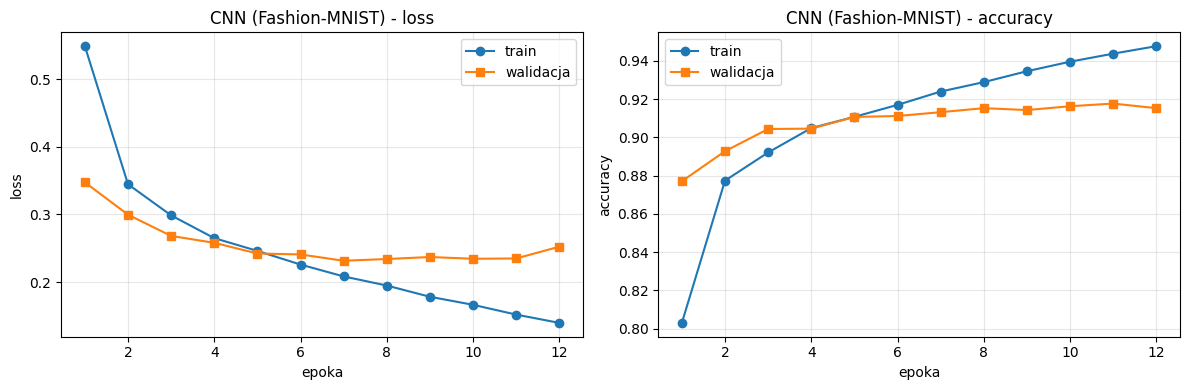

      model  parametry  test accuracy  czas treningu [s]
MLP 256-128     235146         0.8713               21.5
        CNN     421642         0.9097              175.4
Conv2D(32, 3, 1 kanal):   320
Conv2D(64, 3, 32 kanaly): 18496
Dense(128) po Flatten:     401536


In [9]:
# 1. Architektura: dwa bloki splot + pooling, klasyfikator gesty
keras.utils.set_random_seed(SEED)
cnn_f = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),   # 28x28x32
    layers.MaxPooling2D(2),                                    # 14x14x32
    layers.Conv2D(64, 3, padding="same", activation="relu"),   # 14x14x64
    layers.MaxPooling2D(2),                                    # 7x7x64
    layers.Flatten(),                                          # 3136
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="cnn_fashion")

cnn_f.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_cnn_f = cnn_f.fit(xf_train, yf_train, epochs=EPOKI_F, batch_size=128,
                       validation_data=(xf_val, yf_val), verbose=2)
czas_cnn = time.time() - t0
acc_cnn_f = cnn_f.evaluate(xf_te4, yf_test, verbose=0)[1]
print(f"CNN: parametry = {cnn_f.count_params():,}, test acc = {acc_cnn_f:.4f}, czas = {czas_cnn:.1f} s")

# 2. Krzywe uczenia
rysuj_historie(hist_cnn_f, tytul="CNN (Fashion-MNIST)")

# 3. Tabela porownawcza MLP z L3 vs CNN (ten sam zbior, te same epoki)
porownanie = pd.DataFrame({
    "model": ["MLP 256-128", "CNN"],
    "parametry": [mlp_f.count_params(), cnn_f.count_params()],
    "test accuracy": [acc_mlp_f, acc_cnn_f],
    "czas treningu [s]": [czas_mlp, czas_cnn],
})
print(porownanie.round({"test accuracy": 4, "czas treningu [s]": 1}).to_string(index=False))

# 4. Skad parametry w CNN? Sploty sa tanie, drogi jest Dense po Flatten
print("Conv2D(32, 3, 1 kanal):  ", 3 * 3 * 1 * 32 + 32)
print("Conv2D(64, 3, 32 kanaly):", 3 * 3 * 32 * 64 + 64)
print("Dense(128) po Flatten:    ", 7 * 7 * 64 * 128 + 128)

*Weryfikacja hipotezy:* **potwierdzona we wszystkich trzech punktach, choć dokładność wyszła przy dolnej granicy widełek.**

| model | parametry | test accuracy | czas treningu |
|---|---:|---:|---:|
| MLP 256-128 | 235 146 | 0.8713 | 21.5 s |
| CNN | 421 642 | **0.9097** | 175.4 s |

- **Dokładność:** 0.9097 wobec 0.8713, czyli **+3.8 p.p.** - mniej niż zapowiadane 0.91-0.93, ale kierunek się zgadza.
- **Parametry:** 421 642 wobec 235 146, czyli **1.79x więcej** - dokładnie tak, jak przewidywałem. Rachunek z hipotezy zgadza się co do jednego parametru: 320 + 18 496 + 401 536 = 421 642, a `Dense(128)` po `Flatten` to **95%** wszystkich wag sieci.
- **Czas:** 175.4 s wobec 21.5 s (**8x dłużej**) - zgodnie z przewidywaniem, bo sploty mają mało parametrów, ale dużo operacji.
- **Czego nie przewidziałem:** CNN zaczyna się lekko przeuczać - w 12. epoce `accuracy` treningowa 0.9477, walidacyjna 0.9153 (luka 0.03), a minimum `val_loss` wypada już w epoce 7. Sam splot nie chroni więc przed zapamiętywaniem; dlatego w sekcji 3 dochodzą BatchNorm, Dropout i augmentacja.

## 3. CIFAR-10: CNN z BatchNorm, Dropout i augmentacją

### Zbiór danych
CIFAR-10: 60 000 kolorowych obrazów 32x32x3 w 10 klasach (samolot, samochód, ptak, kot, jeleń, pies, żaba, koń, statek, ciężarówka). Znacznie trudniejszy niż Fashion-MNIST: tło, różne pozy, oświetlenie, niska rozdzielczość. MLP osiąga tu ok. 50-55%, prosta CNN ok. 70%, dobre CNN > 90%.

### Augmentacja danych (W3)
Sztucznie powiększamy zbiór treningowy, losowo przekształcając obrazy w sposób, który **nie zmienia etykiety**: odbicie lustrzane w poziomie, małe przesunięcia, obroty, zoom. Model widzi w każdej epoce nieco inne wersje obrazów, co działa jak silna regularyzacja.

W Keras 3 augmentację robią warstwy `RandomFlip`, `RandomTranslation`, `RandomRotation`, `RandomZoom`, ... Umieszczone **wewnątrz modelu** działają tylko w trakcie treningu (`training=True`), a w `predict`/`evaluate` są przezroczyste. Uwaga: przekształcenie musi mieć sens dla danych - odbicie pionowe dla CIFAR (samolot do góry nogami) to zły pomysł, a dla cyfr nawet odbicie poziome zmienia znaczenie.

train: (45000, 32, 32, 3) val: (5000, 32, 32, 3) test: (10000, 32, 32, 3)


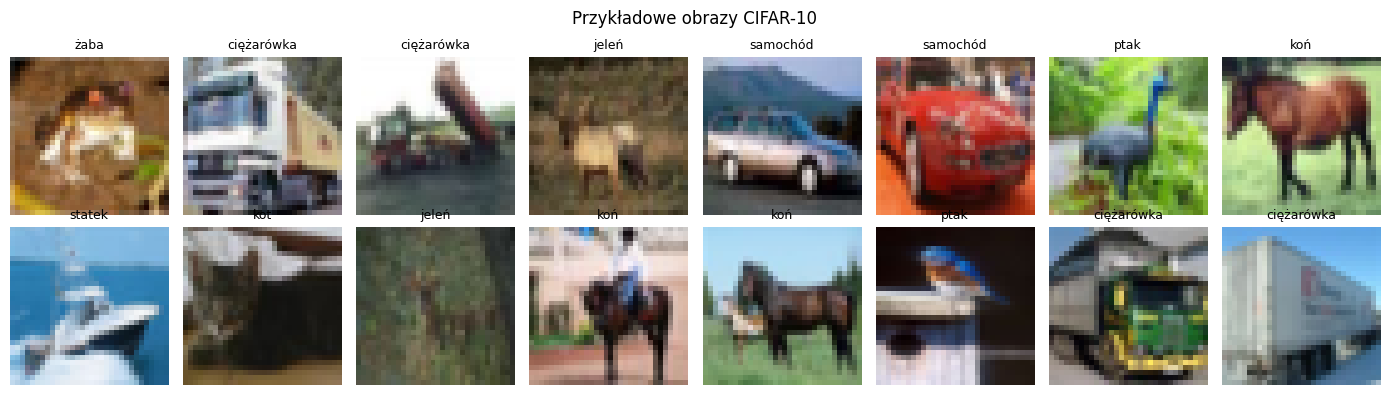

In [10]:
(xc_tr_full, yc_tr_full), (xc_test, yc_test) = keras.datasets.cifar10.load_data()
yc_tr_full, yc_test = yc_tr_full.ravel(), yc_test.ravel()   # etykiety mają kształt (n, 1) -> (n,)
if SZYBKI_TRYB:
    xc_tr_full, yc_tr_full = xc_tr_full[:2000], yc_tr_full[:2000]
    xc_test, yc_test = xc_test[:500], yc_test[:500]

# Surowe obrazy uint8 0..255 zachowujemy do transfer learningu (sekcja 6)
xc_tr_raw, xc_te_raw = xc_tr_full, xc_test

# Do własnych CNN: skalowanie do [0, 1]
xc_tr = xc_tr_full.astype("float32") / 255.0
xc_te = xc_test.astype("float32") / 255.0
n_val_c = len(xc_tr) // 10
xc_train, yc_train = xc_tr[:-n_val_c], yc_tr_full[:-n_val_c]
xc_val, yc_val = xc_tr[-n_val_c:], yc_tr_full[-n_val_c:]

NAZWY_CIFAR = ["samolot", "samochód", "ptak", "kot", "jeleń", "pies", "żaba", "koń", "statek", "ciężarówka"]
print("train:", xc_train.shape, "val:", xc_val.shape, "test:", xc_te.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(xc_train[i]); ax.set_title(NAZWY_CIFAR[yc_train[i]], fontsize=9); ax.axis("off")
plt.suptitle("Przykładowe obrazy CIFAR-10"); plt.tight_layout(); plt.show()

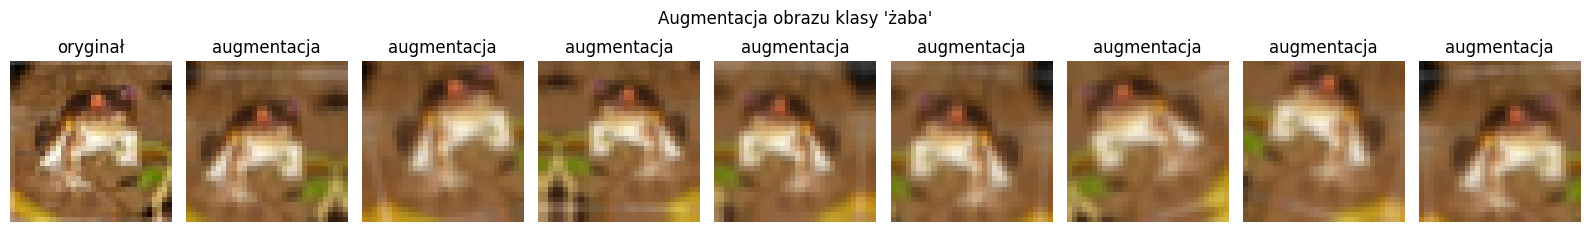

In [11]:
# Potok augmentacji jako mały model Sequential
augmentacja = keras.Sequential([
    layers.RandomFlip("horizontal"),                    # odbicie lewo-prawo
    layers.RandomTranslation(0.1, 0.1),                 # przesunięcie do 10% w pionie i poziomie
    layers.RandomRotation(0.05),                        # obrót do +-5% pełnego kąta (ok. +-18 stopni)
    layers.RandomZoom(0.1),                             # zoom +-10%
], name="augmentacja")

# Podgląd: ten sam obraz po 8 losowych augmentacjach (training=True wymusza losowość)
obraz = xc_train[:1]
fig, axes = plt.subplots(1, 9, figsize=(16, 2.4))
axes[0].imshow(obraz[0]); axes[0].set_title("oryginał"); axes[0].axis("off")
for ax in axes[1:]:
    aug = augmentacja(obraz, training=True)
    ax.imshow(np.clip(keras.ops.convert_to_numpy(aug)[0], 0, 1)); ax.set_title("augmentacja"); ax.axis("off")
plt.suptitle(f"Augmentacja obrazu klasy '{NAZWY_CIFAR[yc_train[0]]}'"); plt.tight_layout(); plt.show()

**Co obserwować:** każde wywołanie z `training=True` daje inny obraz - w każdej epoce sieć zobaczy więc inną wersję tego samego zdjęcia. Przesunięcia i obroty wypełniają brzegi obrazu (domyślnie odbiciem, `fill_mode="reflect"`). Przekształcenia są niewielkie - obraz ma pozostać rozpoznawalny dla człowieka. Zbyt agresywna augmentacja prowadzi do niedouczenia.

### Baseline: prosta CNN bez BatchNorm i augmentacji

Zbudujemy ją w **Functional API** (W3): każda warstwa jest funkcją wywoływaną na tensorze, a model definiujemy przez wejście i wyjście. Functional API przyda się do bloków residualnych i do wyciągania map cech z warstw pośrednich. Nazywamy warstwy (`name=...`), żeby łatwo się do nich odwołać.

parametry: 356,810
czas: 395 s, test acc: 0.7011


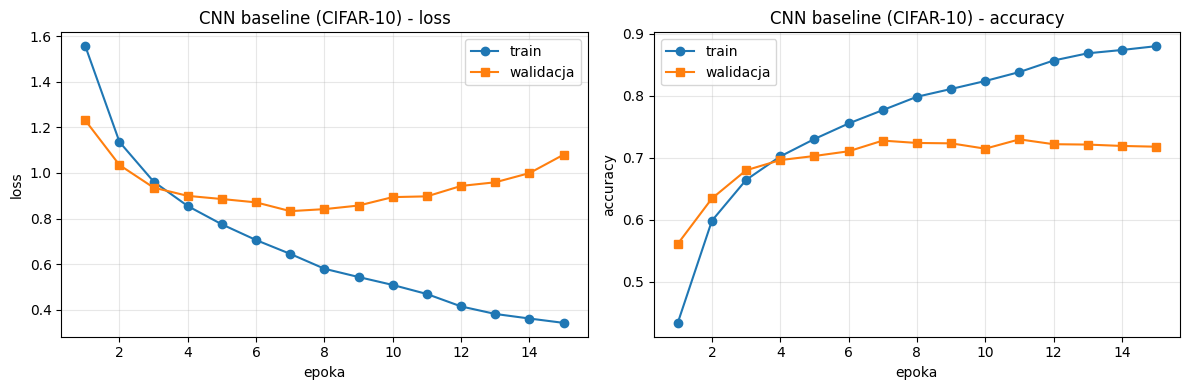

In [12]:
EPOKI_C = 2 if SZYBKI_TRYB else 15

keras.utils.set_random_seed(SEED)
we = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1")(we)
x = layers.MaxPooling2D(2)(x)                                                     # 16x16
x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2")(x)
x = layers.MaxPooling2D(2)(x)                                                     # 8x8
x = layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3")(x)
x = layers.MaxPooling2D(2)(x)                                                     # 4x4
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
wy = layers.Dense(10, activation="softmax")(x)
cnn_base = keras.Model(we, wy, name="cnn_baseline")
cnn_base.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("parametry:", f"{cnn_base.count_params():,}")

t0 = time.time()
hist_base = cnn_base.fit(xc_train, yc_train, epochs=EPOKI_C, batch_size=128,
                         validation_data=(xc_val, yc_val), verbose=0)
acc_base = cnn_base.evaluate(xc_te, yc_test, verbose=0)[1]
print(f"czas: {time.time() - t0:.0f} s, test acc: {acc_base:.4f}")
rysuj_historie(hist_base, tytul="CNN baseline (CIFAR-10)")

**Co obserwować:** porównaj krzywe z krzywymi z Fashion-MNIST. Na CIFAR-10 luka między train a walidacją rośnie szybko - zbiór jest trudniejszy, a sieć bez regularyzacji zaczyna zapamiętywać obrazy treningowe. Zapisz epokę, w której `val_loss` osiąga minimum - przyda się do porównania z modelem z zad. 3.1.

### Zadanie 3.1 - CNN z BatchNorm, Dropout i augmentacją

Zbuduj w **Functional API** model `model_cifar`:
- na wejściu (32, 32, 3) warstwa `augmentacja` (zdefiniowana wyżej),
- trzy bloki; blok $i$ (filtry $F_i \in \{32, 64, 128\}$):
  `Conv2D(F, 3, same) -> BatchNormalization -> ReLU -> Conv2D(F, 3, same) -> BatchNormalization -> ReLU -> MaxPooling2D(2) -> Dropout(0.2 + 0.1 * i)`; ostatnią warstwę `Conv2D` nazwij `"ostatni_conv"`,
- głowa: `Flatten -> Dense(128, relu) -> Dropout(0.5) -> Dense(10, softmax)`.

Wytrenuj `EPOKI_C31` epok (Adam lr = 1e-3, batch 128) z callbackami `EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True)` i `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)`. Narysuj krzywe i porównaj test accuracy z baseline'em.

**Kryteria sukcesu (pełny tryb):** test accuracy >= 0.80; luka między train a val wyraźnie mniejsza niż w baseline.

**Wskazówki:** w Functional API `x = layers.BatchNormalization()(x)`, a aktywację jako osobną warstwę: `layers.Activation("relu")(x)`. Pętla `for i, F in enumerate([32, 64, 128])` skraca kod. Uwaga: z augmentacją train accuracy bywa **niższa** od walidacyjnej - model trenuje na trudniejszych, przekształconych obrazach.

parametry model_cifar: 551,914
Epoch 1/40
352/352 - 120s - 340ms/step - accuracy: 0.2430 - loss: 1.9867 - val_accuracy: 0.2004 - val_loss: 2.3000 - learning_rate: 0.0010
Epoch 2/40
352/352 - 141s - 402ms/step - accuracy: 0.3214 - loss: 1.7486 - val_accuracy: 0.3262 - val_loss: 1.8761 - learning_rate: 0.0010
Epoch 3/40
352/352 - 116s - 330ms/step - accuracy: 0.3657 - loss: 1.6448 - val_accuracy: 0.3978 - val_loss: 1.8247 - learning_rate: 0.0010
Epoch 4/40
352/352 - 116s - 328ms/step - accuracy: 0.4037 - loss: 1.5617 - val_accuracy: 0.4762 - val_loss: 1.6649 - learning_rate: 0.0010
Epoch 5/40
352/352 - 114s - 324ms/step - accuracy: 0.4432 - loss: 1.4795 - val_accuracy: 0.4896 - val_loss: 1.5178 - learning_rate: 0.0010
Epoch 6/40
352/352 - 113s - 322ms/step - accuracy: 0.4724 - loss: 1.4160 - val_accuracy: 0.5330 - val_loss: 1.3183 - learning_rate: 0.0010
Epoch 7/40
352/352 - 113s - 322ms/step - accuracy: 0.5029 - loss: 1.3516 - val_accuracy: 0.5966 - val_loss: 1.1690 - learning_rate: 0.0

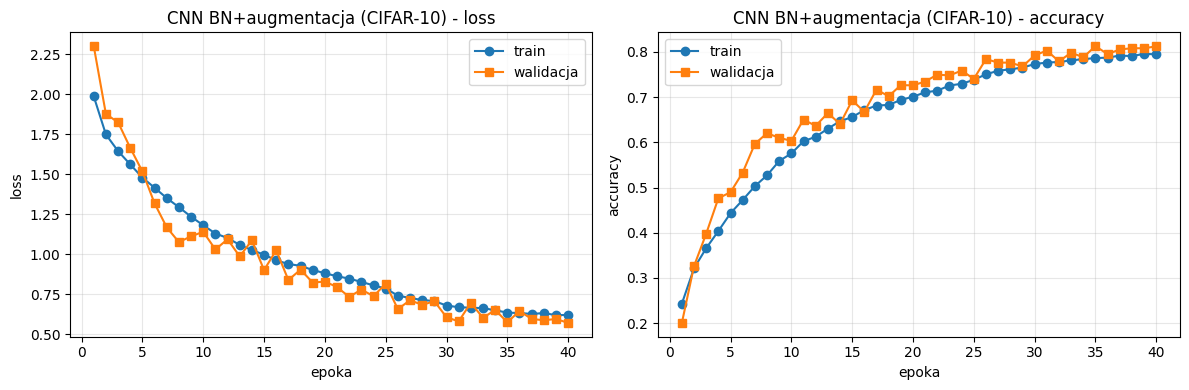

test accuracy: baseline = 0.7011, model_cifar = 0.8003
luka train - walidacja (ostatnia epoka): baseline = +0.162, model_cifar = -0.018
minimum val_loss w epoce 40 z 40
           model  parametry  test accuracy  obrazy treningowe  zbior testowy
    CNN baseline     356810         0.7011              45000          10000
CNN BN+aug (3.1)     551914         0.8003              45000          10000


In [13]:
EPOKI_C31 = 2 if SZYBKI_TRYB else 40


def blok_splotowy(x, filtry, dropout, nazwa_1, nazwa_2):
    # Blok: Conv2D -> BN -> ReLU -> Conv2D -> BN -> ReLU -> MaxPooling2D -> Dropout
    x = layers.Conv2D(filtry, 3, padding="same", use_bias=False, name=nazwa_1)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filtry, 3, padding="same", use_bias=False, name=nazwa_2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)


keras.utils.set_random_seed(SEED)
we = keras.Input(shape=(32, 32, 3))
x = augmentacja(we)                       # aktywne tylko podczas treningu
for i, F in enumerate([32, 64, 128]):
    x = blok_splotowy(x, F, dropout=0.2 + 0.1 * i,
                      nazwa_1=f"conv_b{i + 1}_1",
                      nazwa_2="ostatni_conv" if i == 2 else f"conv_b{i + 1}_2")
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
wy = layers.Dense(10, activation="softmax")(x)
model_cifar = keras.Model(we, wy, name="cnn_bn_aug")

model_cifar.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("parametry model_cifar:", f"{model_cifar.count_params():,}")

callbacki = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

t0 = time.time()
hist_cifar = model_cifar.fit(xc_train, yc_train, epochs=EPOKI_C31, batch_size=128,
                             validation_data=(xc_val, yc_val), callbacks=callbacki, verbose=2)
print(f"czas: {time.time() - t0:.0f} s, epok wykonanych: {len(hist_cifar.history['loss'])}")

acc_cifar = model_cifar.evaluate(xc_te, yc_test, verbose=0)[1]
rysuj_historie(hist_cifar, tytul="CNN BN+augmentacja (CIFAR-10)")

# Porownanie z baseline'em: dokladnosc i luka train - walidacja
ep_min_val = int(np.argmin(hist_cifar.history["val_loss"])) + 1
luka_base = hist_base.history["accuracy"][-1] - hist_base.history["val_accuracy"][-1]
luka_cifar = hist_cifar.history["accuracy"][-1] - hist_cifar.history["val_accuracy"][-1]
print(f"test accuracy: baseline = {acc_base:.4f}, model_cifar = {acc_cifar:.4f}")
print(f"luka train - walidacja (ostatnia epoka): baseline = {luka_base:+.3f}, model_cifar = {luka_cifar:+.3f}")
print(f"minimum val_loss w epoce {ep_min_val} z {len(hist_cifar.history['loss'])}")

wyniki_cifar = [
    {"model": "CNN baseline", "parametry": cnn_base.count_params(),
     "test accuracy": acc_base, "obrazy treningowe": len(xc_train), "zbior testowy": len(xc_te)},
    {"model": "CNN BN+aug (3.1)", "parametry": model_cifar.count_params(),
     "test accuracy": acc_cifar, "obrazy treningowe": len(xc_train), "zbior testowy": len(xc_te)},
]
print(pd.DataFrame(wyniki_cifar).round(4).to_string(index=False))

---
## Przerwa (10 min)
---

## 4. Blok residualny i GlobalAveragePooling

### Problem głębokich sieci
Intuicyjnie głębsza sieć powinna być co najmniej tak dobra jak płytsza (dodatkowe warstwy mogłyby nauczyć się identyczności). W praktyce bardzo głębokie "zwykłe" sieci trenują się **gorzej** - gradient przechodzący przez dziesiątki warstw zanika lub się rozprasza (problem degradacji, W2).

### Połączenie residualne (He i in., ResNet, 2015)
Zamiast uczyć bezpośrednio odwzorowania $H(x)$, blok uczy **reszty** $F(x) = H(x) - x$:

$$y = \text{ReLU}\big(F(x) + x\big).$$

- Jeśli najlepsze jest "nic nie robić", wystarczy $F(x) = 0$ (łatwe do nauczenia - wagi bliskie zera).
- Gradient płynie przez dodawanie bez zmian: $\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + I$ - "autostrada" dla gradientu.

Gdy $F(x)$ zmienia liczbę kanałów lub rozdzielczość (stride 2), skrót musi być **projekcją**: `Conv2D(F, 1, strides=2)` (splot 1x1) dopasowuje wymiary $x$ do $F(x)$.

### GlobalAveragePooling2D
Zamiast `Flatten` (który z mapy 8x8x128 robi wektor 8192 liczb i wymaga ogromnej warstwy gęstej) liczymy **średnią każdej mapy cech**: z $H \times W \times C$ dostajemy wektor $C$ liczb. Zalety: dużo mniej parametrów, mniejsze przeuczenie, niezależność od rozmiaru wejścia. Tak kończy się ResNet, MobileNet i większość nowoczesnych CNN.

In [14]:
def blok_identycznosciowy(x, filtry):
    # Blok residualny bez zmiany wymiarów: wejście i wyjście mają 'filtry' kanałów
    skrot = x                                                    # gałąź skrótu: identyczność
    y = layers.Conv2D(filtry, 3, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filtry, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    y = layers.Add()([y, skrot])                                 # F(x) + x
    return layers.Activation("relu")(y)

# Demonstracja na małym modelu: kształty muszą się zgadzać, inaczej Add zgłosi błąd
we = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(32, 3, padding="same", activation="relu")(we)   # 32 kanały
x = blok_identycznosciowy(x, 32)
wy = layers.GlobalAveragePooling2D()(x)
keras.Model(we, wy, name="demo_resblock").summary()

# Porównanie liczby parametrów głowy: Flatten vs GAP na mapie 8x8x128 i 10 klasach
print("Flatten + Dense(10):", 8 * 8 * 128 * 10 + 10, "parametrów")
print("GAP + Dense(10):    ", 128 * 10 + 10, "parametrów")

Model: "demo_resblock"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 32, 32, 32)        │             896 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ conv2d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_6         │ (None, 32, 32, 32)        │             128 │ conv2d_6[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_6 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_6[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_6[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_7         │ (None, 32, 32, 32)        │             128 │ conv2d_7[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 32, 32, 32)        │               0 │ batch_normalization_7[0][… │
│                               │                           │                 │ conv2d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_7 (Activation)     │ (None, 32, 32, 32)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 32)                │               0 │ activation_7[0][0]         │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 19,584 (76.50 KB)

 Trainable params: 19,456 (76.00 KB)

 Non-trainable params: 128 (512.00 B)

Flatten + Dense(10): 81930 parametrów
GAP + Dense(10):     1290 parametrów


### Zadanie 4.1 - Mini-ResNet

1. Napisz funkcję `blok_rezydualny(x, filtry, stride=1)`, która działa jak `blok_identycznosciowy`, ale:
   - pierwszy `Conv2D` ma `strides=stride`,
   - jeśli `stride != 1` lub liczba kanałów `x` (`x.shape[-1]`) jest różna od `filtry`, skrót to `Conv2D(filtry, 1, strides=stride, use_bias=False)` + `BatchNormalization`.
2. Zbuduj `model_res`: `Input(32,32,3) -> augmentacja -> Conv2D(32, 3, same) -> BN -> ReLU -> blok(32) -> blok(64, stride=2) -> blok(128, stride=2) -> GlobalAveragePooling2D -> Dropout(0.3) -> Dense(10, softmax)`.
3. Wytrenuj tak samo jak w zad. 3.1 (`EPOKI_C31`, te same callbacki).
4. Dopisz do tabeli: model, liczba parametrów, test accuracy (baseline, model z 3.1, mini-ResNet).

**Kryteria sukcesu (pełny tryb):** model ma kilka razy mniej parametrów niż `model_cifar`, a test accuracy jest porównywalna lub lepsza (>= 0.80).

**Wskazówka:** narysuj schemat modelu: `keras.utils.plot_model(model_res, show_shapes=True)` - działa w Colab (wymaga pakietu pydot/graphviz, który Colab zwykle ma); jeśli nie działa, wystarczy `summary()`.

Model: "mini_resnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ augmentacja (Sequential)      │ (None, 32, 32, 3)         │               0 │ input_layer_8[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 32, 32, 32)        │             864 │ augmentacja[1][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_8         │ (None, 32, 32, 32)        │             128 │ conv2d_8[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_8 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_8[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_8[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_9         │ (None, 32, 32, 32)        │             128 │ conv2d_9[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_9 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_9[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 32, 32, 32)        │           9,216 │ activation_9[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_10        │ (None, 32, 32, 32)        │             128 │ conv2d_10[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 32, 32, 32)        │               0 │ batch_normalization_10[0]… │
│                               │                           │                 │ activation_8[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_10 (Activation)    │ (None, 32, 32, 32)        │               0 │ add_1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_11 (Conv2D)            │ (None, 16, 16, 64)        │          18,432 │ activation_10[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_11        │ (None, 16, 16, 64)        │             256 │ conv2d_11[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_11 (Activation)    │ (None, 16, 16, 64)        │               

 Total params: 309,994 (1.18 MB)

 Trainable params: 308,650 (1.18 MB)

 Non-trainable params: 1,344 (5.25 KB)

Epoch 1/40
352/352 - 91s - 257ms/step - accuracy: 0.4221 - loss: 1.5691 - val_accuracy: 0.2484 - val_loss: 2.3983 - learning_rate: 0.0010
Epoch 2/40
352/352 - 49s - 138ms/step - accuracy: 0.5524 - loss: 1.2488 - val_accuracy: 0.4886 - val_loss: 1.4168 - learning_rate: 0.0010
Epoch 3/40
352/352 - 156s - 442ms/step - accuracy: 0.6008 - loss: 1.1168 - val_accuracy: 0.4740 - val_loss: 1.6536 - learning_rate: 0.0010
Epoch 4/40
352/352 - 155s - 442ms/step - accuracy: 0.6337 - loss: 1.0355 - val_accuracy: 0.5408 - val_loss: 1.3636 - learning_rate: 0.0010
Epoch 5/40
352/352 - 155s - 440ms/step - accuracy: 0.6592 - loss: 0.9672 - val_accuracy: 0.5402 - val_loss: 1.5775 - learning_rate: 0.0010
Epoch 6/40
352/352 - 201s - 572ms/step - accuracy: 0.6811 - loss: 0.9128 - val_accuracy: 0.5044 - val_loss: 1.8519 - learning_rate: 0.0010
Epoch 7/40
352/352 - 154s - 438ms/step - accuracy: 0.6956 - loss: 0.8704 - val_accuracy: 0.5788 - val_loss: 1.3656 - learning_rate: 0.0010
Epoch 8/40
352/352 - 155s - 4

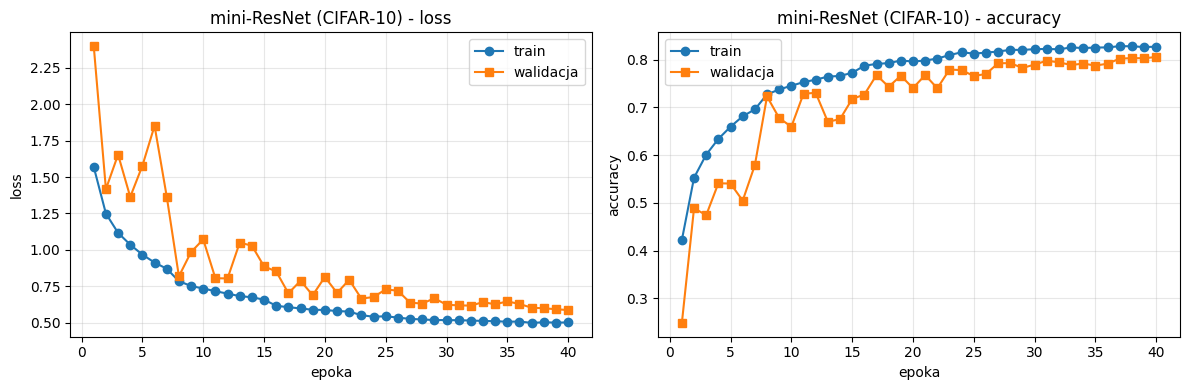

parametry: model_cifar = 551,914, model_res = 309,994 (1.8x mniej)
test accuracy: baseline = 0.7011, model_cifar = 0.8003, model_res = 0.7952
            model  parametry  test accuracy  obrazy treningowe  zbior testowy
     CNN baseline     356810         0.7011              45000          10000
 CNN BN+aug (3.1)     551914         0.8003              45000          10000
mini-ResNet (4.1)     309994         0.7952              45000          10000


In [15]:
def blok_rezydualny(x, filtry, stride=1):
    # Blok residualny; skrot wymaga projekcji 1x1, gdy zmienia sie rozdzielczosc lub liczba kanalow
    skrot = x
    y = layers.Conv2D(filtry, 3, strides=stride, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filtry, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or int(x.shape[-1]) != filtry:
        skrot = layers.Conv2D(filtry, 1, strides=stride, use_bias=False)(x)
        skrot = layers.BatchNormalization()(skrot)
    y = layers.Add()([y, skrot])                  # F(x) + x
    return layers.Activation("relu")(y)


keras.utils.set_random_seed(SEED)
we = keras.Input(shape=(32, 32, 3))
x = augmentacja(we)
x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = blok_rezydualny(x, 32)                        # 32x32x32
x = blok_rezydualny(x, 64, stride=2)              # 16x16x64
x = blok_rezydualny(x, 128, stride=2)             # 8x8x128
x = layers.GlobalAveragePooling2D()(x)            # wektor 128 zamiast 8192
x = layers.Dropout(0.3)(x)
wy = layers.Dense(10, activation="softmax")(x)
model_res = keras.Model(we, wy, name="mini_resnet")

model_res.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_res.summary()

# Nowe obiekty callbackow - stare maja juz zapamietany stan (najlepszy wynik, licznik cierpliwosci)
callbacki_res = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

t0 = time.time()
hist_res = model_res.fit(xc_train, yc_train, epochs=EPOKI_C31, batch_size=128,
                         validation_data=(xc_val, yc_val), callbacks=callbacki_res, verbose=2)
print(f"czas: {time.time() - t0:.0f} s, epok wykonanych: {len(hist_res.history['loss'])}")

acc_res = model_res.evaluate(xc_te, yc_test, verbose=0)[1]
rysuj_historie(hist_res, tytul="mini-ResNet (CIFAR-10)")

print(f"parametry: model_cifar = {model_cifar.count_params():,}, "
      f"model_res = {model_res.count_params():,} "
      f"({model_cifar.count_params() / model_res.count_params():.1f}x mniej)")
print(f"test accuracy: baseline = {acc_base:.4f}, model_cifar = {acc_cifar:.4f}, model_res = {acc_res:.4f}")

wyniki_cifar.append({"model": "mini-ResNet (4.1)", "parametry": model_res.count_params(),
                     "test accuracy": acc_res, "obrazy treningowe": len(xc_train),
                     "zbior testowy": len(xc_te)})
print(pd.DataFrame(wyniki_cifar).round(4).to_string(index=False))

## 5. Co "widzi" sieć? Filtry i mapy cech

### Filtry pierwszej warstwy
Wagi pierwszej warstwy `Conv2D` mają kształt `(3, 3, 3, 32)`: 32 filtry 3x3 działające na 3 kanałach RGB. Każdy filtr możemy narysować jako maleńki obrazek RGB (po przeskalowaniu do [0, 1]). W dobrze wytrenowanych sieciach (szczególnie z większymi filtrami, np. 7x7 lub 11x11 w AlexNet) przypominają detektory krawędzi w różnych orientacjach i plam koloru - jak Sobel z sekcji 1, ale **nauczone** z danych.

### Mapy cech (aktywacje)
Mapa cech to wyjście warstwy dla konkretnego obrazu - kanał $c$ pokazuje, gdzie na obrazie "zadziałał" filtr $c$. Aby je zobaczyć, budujemy model pomocniczy z tym samym wejściem i wyjściem z warstwy pośredniej - to możliwe dzięki Functional API:
```python
ekstraktor = keras.Model(inputs=model.inputs, outputs=model.get_layer("conv1").output)
```

kształt wag conv1: (3, 3, 3, 32)


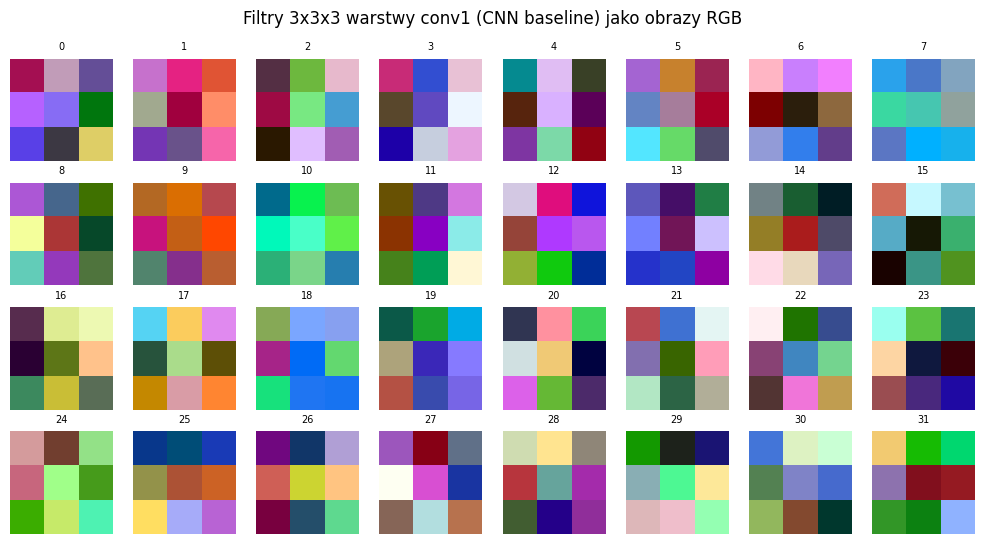

In [16]:
# Filtry pierwszej warstwy baseline'u
W, b = cnn_base.get_layer("conv1").get_weights()   # W: (3, 3, 3, 32)
print("kształt wag conv1:", W.shape)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for i, ax in enumerate(axes.flat):
    f = W[:, :, :, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # skalowanie do [0, 1] dla każdego filtra
    ax.imshow(f, interpolation="nearest"); ax.axis("off"); ax.set_title(str(i), fontsize=7)
plt.suptitle("Filtry 3x3x3 warstwy conv1 (CNN baseline) jako obrazy RGB"); plt.tight_layout(); plt.show()

**Co obserwować:** filtry 3x3 są zbyt małe, by zobaczyć "ładne" detektory krawędzi, ale zwykle widać filtry wrażliwe na konkretny kolor (jednolite plamy) oraz filtry z wyraźnym kontrastem jasne/ciemne w jednym kierunku - odpowiedniki filtrów Sobela. Filtry wyglądające jak szum mogą być słabo wykorzystywane przez sieć.

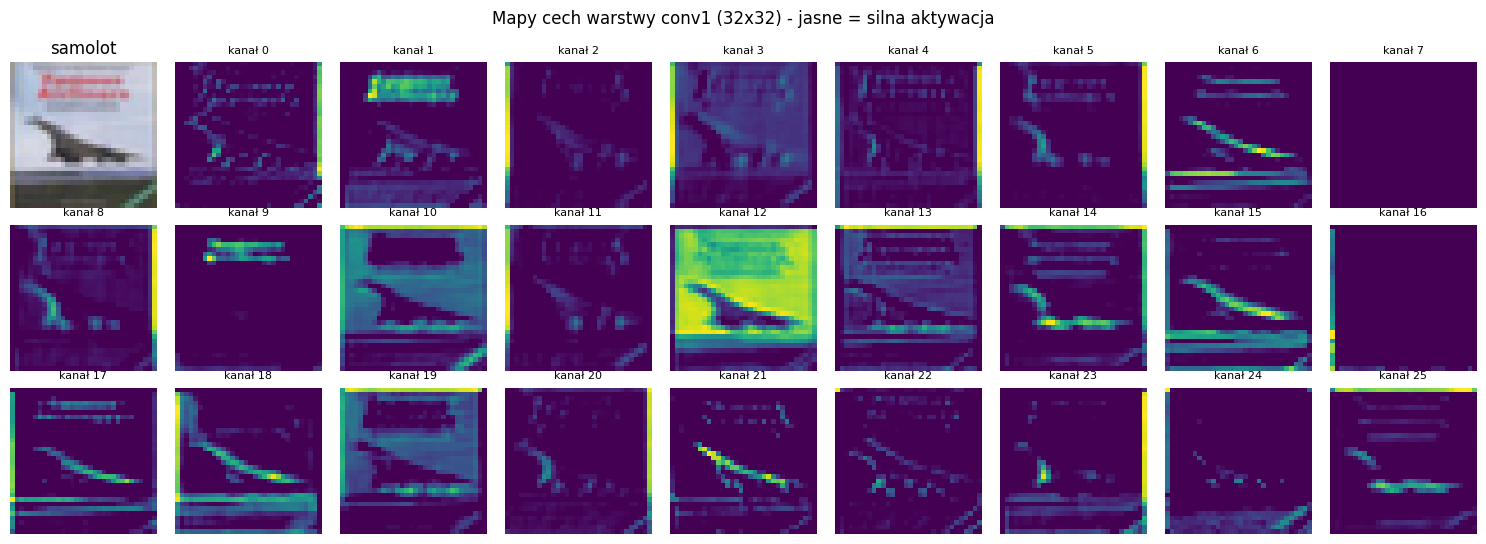

In [17]:
# Mapy cech warstwy conv1 dla jednego obrazu testowego
ekstraktor = keras.Model(inputs=cnn_base.input, outputs=cnn_base.get_layer("conv1").output)
obraz = xc_te[3:4]                                  # batch z jednym obrazem
mapy = keras.ops.convert_to_numpy(ekstraktor(obraz))[0]   # (32, 32, 32)

fig, axes = plt.subplots(3, 9, figsize=(15, 5.5))
axes[0, 0].imshow(obraz[0]); axes[0, 0].set_title(NAZWY_CIFAR[yc_test[3]]); axes[0, 0].axis("off")
for k, ax in enumerate(axes.flat[1:]):
    ax.imshow(mapy[:, :, k], cmap="viridis"); ax.set_title(f"kanał {k}", fontsize=8); ax.axis("off")
plt.suptitle("Mapy cech warstwy conv1 (32x32) - jasne = silna aktywacja"); plt.tight_layout(); plt.show()

**Co obserwować:** część kanałów reaguje na krawędzie o określonej orientacji, część na jasne lub ciemne obszary, część na konkretne kolory (np. niebo, trawa). Niektóre kanały są niemal puste - ReLU wyzerował ujemne odpowiedzi, bo na tym obrazie nie ma wzorca, którego szuka filtr.

### Zadanie 5.1 - Mapy cech płytkie vs głębokie

Dla modelu `model_cifar` z zad. 3.1:
1. Zbuduj ekstraktor zwracający **dwa** wyjścia: pierwszą warstwę `Conv2D` w modelu (nazwa `"conv_b1_1"` w rozwiązaniu wzorcowym - sprawdź swoją nazwę w `summary()`) oraz `"ostatni_conv"`.
2. Dla jednego obrazu testowego narysuj po 8 map cech z każdej warstwy (dwa wiersze) z informacją o rozdzielczości w tytule.
3. Odpowiedz w markdown: czym różnią się mapy płytkie i głębokie (rozdzielczość, czytelność dla człowieka, pole recepcyjne)?

**Kryteria sukcesu:** wykres z dwoma wierszami i podpisami; poprawna interpretacja.

**Wskazówki:** `keras.Model(inputs=model.inputs, outputs=[warstwa1.output, warstwa2.output])` zwraca listę. Jeśli nie pamiętasz nazw, użyj `[l.name for l in model_cifar.layers if isinstance(l, layers.Conv2D)]`. Warstwa augmentacji w trybie predykcji nie zmienia obrazu.

warstwy Conv2D w model_cifar: ['conv_b1_1', 'conv_b1_2', 'conv_b2_1', 'conv_b2_2', 'conv_b3_1', 'ostatni_conv']
mapy plytkie: (1, 32, 32, 32) | mapy glebokie: (1, 8, 8, 128)


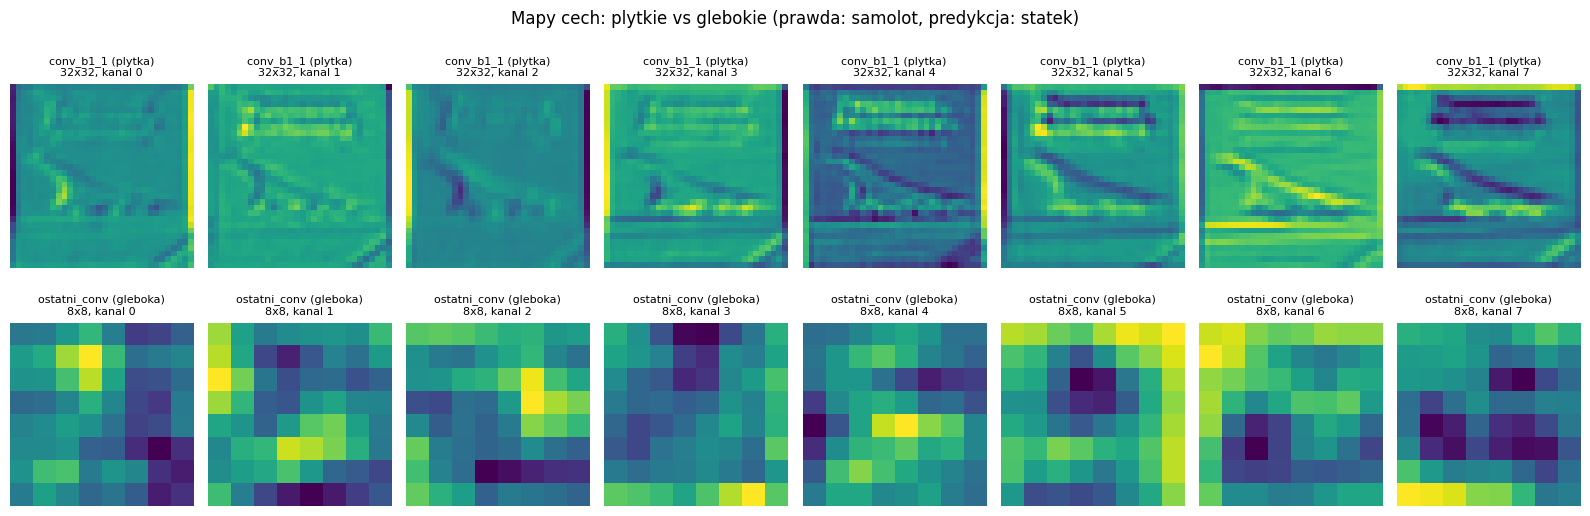

In [18]:
# Nazwy warstw splotowych w model_cifar (do sprawdzenia, czy "conv_b1_1" i "ostatni_conv" istnieja)
nazwy_conv = [l.name for l in model_cifar.layers if isinstance(l, layers.Conv2D)]
print("warstwy Conv2D w model_cifar:", nazwy_conv)

# Ekstraktor z dwoma wyjsciami: pierwsza warstwa splotowa i ostatnia
ekstraktor_51 = keras.Model(
    inputs=model_cifar.input,
    outputs=[model_cifar.get_layer("conv_b1_1").output,
             model_cifar.get_layer("ostatni_conv").output],
)

IDX = 3                                      # przykladowy obraz testowy
obraz = xc_te[IDX:IDX + 1]
mapy_plytkie, mapy_glebokie = ekstraktor_51(obraz, training=False)
mapy_plytkie = keras.ops.convert_to_numpy(mapy_plytkie)
mapy_glebokie = keras.ops.convert_to_numpy(mapy_glebokie)
pred = int(np.argmax(model_cifar.predict(obraz, verbose=0)[0]))
print("mapy plytkie:", mapy_plytkie.shape, "| mapy glebokie:", mapy_glebokie.shape)

fig, axes = plt.subplots(2, 8, figsize=(16, 5.6))
for wiersz, (mapy, opis) in enumerate([(mapy_plytkie, "conv_b1_1 (plytka)"),
                                       (mapy_glebokie, "ostatni_conv (gleboka)")]):
    for k in range(8):
        ax = axes[wiersz, k]
        ax.imshow(mapy[0, :, :, k], cmap="viridis")
        ax.set_title(f"{opis}\n{mapy.shape[1]}x{mapy.shape[2]}, kanal {k}", fontsize=8)
        ax.axis("off")
plt.suptitle(f"Mapy cech: plytkie vs glebokie (prawda: {NAZWY_CIFAR[yc_test[IDX]]}, "
             f"predykcja: {NAZWY_CIFAR[pred]})")
plt.tight_layout(); plt.show()

*Interpretacja (zad. 5.1):*

- **Mapy płytkie** (`conv_b1_1`, rozdzielczość 32x32) zachowują rozmiar wejścia - widać na nich kontury,
  krawędzie i plamy koloru dokładnie tam, gdzie występują w obrazie, więc są czytelne „piksel w piksel".
  Pole recepcyjne jednego neuronu to zaledwie 3x3 piksele, dlatego każdy kanał jest prostym detektorem
  (krawędź o danej orientacji, konkretny kolor) - jak filtry Sobela z sekcji 1.
- **Mapy głębokie** (`ostatni_conv`, rozdzielczość 8x8) są 4 razy mniejsze w każdym wymiarze: jedna komórka
  streszcza już cały obraz (pole recepcyjne 32x32, czyli pełne wejście), a kanał odpowiada abstrakcyjnemu
  wzorcowi złożonemu z wielu krawędzi (np. „futro", „skrzydło", „koło"). Pojedyncza mapa jest nieczytelna dla
  człowieka - dopiero po spojrzeniu na wszystkie kanały widać, że aktywacje skupiają się na obiekcie, a nie na tle.


## 6. Transfer learning z MobileNetV2

### Idea (W4)
Sieć wytrenowana na ImageNet (1,28 mln obrazów, 1000 klas) nauczyła się w warstwach splotowych **ogólnych cech wizualnych**: krawędzi, tekstur, części obiektów. Te cechy są przydatne także w innych zadaniach. Zamiast uczyć od zera, bierzemy pretrenowaną "bazę" (bez głowy klasyfikacyjnej) i:

1. **Ekstrakcja cech:** zamrażamy bazę (`base.trainable = False`) i uczymy tylko nową, małą głowę (GAP + Dense). Szybkie, działa dobrze nawet przy małej liczbie obrazów.
2. **Fine-tuning:** odmrażamy górne warstwy bazy i douczamy całość z **bardzo małym** learning rate (np. 1e-5), żeby nie zniszczyć pretrenowanych wag dużymi gradientami z losowo zainicjalizowanej głowy. Dlatego fine-tuning robimy **dopiero po** wytrenowaniu głowy.

### MobileNetV2
Lekka architektura (ok. 2,3 mln parametrów bez głowy) zaprojektowana dla urządzeń mobilnych: **sploty separowalne głębokościowo** (depthwise + pointwise 1x1, wielokrotnie mniej obliczeń niż zwykły splot) oraz **odwrócone bloki residualne** z wąskim gardłem. Dobry kompromis szybkość/dokładność - idealny do Colab.

### Przygotowanie obrazów
- Wagi ImageNet dla MobileNetV2 są dostępne dla rozdzielczości 96, 128, 160, 192, 224. Obrazy CIFAR (32x32) **przeskalujemy do 96x96** - w 32x32 po pięciokrotnym zmniejszeniu rozdzielczości w sieci zostałaby mapa 1x1, a cechy ImageNet nie pasowałyby do skali obiektów.
- Każdy model z `keras.applications` ma własną funkcję `preprocess_input`, która przekształca piksele 0..255 tak, jak podczas treningu na ImageNet. Dla MobileNetV2 to skalowanie do $[-1, 1]$: $x' = x/127.5 - 1$. **Typowy błąd:** podanie obrazów już podzielonych przez 255 - wtedy wszystkie wartości lądują w okolicy $-1$ i transfer prawie nie działa.

### Podzbiór
Żeby trening trwał w Colab kilka minut, użyjemy podzbioru CIFAR-10 (10 000 obrazów treningowych, 2 000 testowych). Przetwarzanie robimy w potoku `tf.data`: skalowanie i `preprocess_input` wykonują się "w locie" dla każdego batcha.

In [19]:
ROZMIAR = 96                                        # rozdzielczość wejścia MobileNetV2
N_TL_TRAIN = 300 if SZYBKI_TRYB else 10000
N_TL_TEST = 100 if SZYBKI_TRYB else 2000
BATCH_TL = 64
preprocess_input = keras.applications.mobilenet_v2.preprocess_input

# Losowy, ale powtarzalny podzbiór (surowe obrazy uint8 0..255!)
rng = np.random.default_rng(SEED)
idx_tr = rng.permutation(len(xc_tr_raw))[:N_TL_TRAIN]
idx_te = rng.permutation(len(xc_te_raw))[:N_TL_TEST]
x_tl, y_tl = xc_tr_raw[idx_tr], yc_tr_full[idx_tr]
x_tl_te, y_tl_te = xc_te_raw[idx_te], yc_test[idx_te]
n_val_tl = len(x_tl) // 10
x_tl_tr, y_tl_tr = x_tl[:-n_val_tl], y_tl[:-n_val_tl]
x_tl_va, y_tl_va = x_tl[-n_val_tl:], y_tl[-n_val_tl:]

def przygotuj(x, y):
    # uint8 32x32 -> float32 96x96 -> skala [-1, 1] wymagana przez MobileNetV2
    x = tf.image.resize(tf.cast(x, tf.float32), (ROZMIAR, ROZMIAR))
    return preprocess_input(x), y

def zrob_ds(x, y, tasuj=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if tasuj:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(BATCH_TL).map(przygotuj, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

ds_tl_tr = zrob_ds(x_tl_tr, y_tl_tr, tasuj=True)
ds_tl_va = zrob_ds(x_tl_va, y_tl_va)
ds_tl_te = zrob_ds(x_tl_te, y_tl_te)

xb, yb = next(iter(ds_tl_tr))
print("batch:", xb.shape, "| zakres po preprocess_input:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))
print("train/val/test:", len(x_tl_tr), len(x_tl_va), len(x_tl_te))

batch: (64, 96, 96, 3) | zakres po preprocess_input: -1.0 - 1.0
train/val/test: 9000 1000 2000


In [20]:
# Pretrenowana baza: include_top=False usuwa głowę klasyfikacyjną ImageNet (1000 klas)
baza = keras.applications.MobileNetV2(input_shape=(ROZMIAR, ROZMIAR, 3),
                                      include_top=False, weights="imagenet")
baza.trainable = False                               # zamrażamy WSZYSTKIE wagi bazy
print("warstw w bazie:", len(baza.layers))
print("wyjście bazy:", baza.output.shape)            # (None, 3, 3, 1280) dla 96x96
print(f"parametry bazy: {baza.count_params():,}, trenowalne: {sum(int(np.prod(w.shape)) for w in baza.trainable_weights)}")

warstw w bazie: 154
wyjście bazy: (None, 3, 3, 1280)
parametry bazy: 2,257,984, trenowalne: 0


**Co obserwować:** baza zamienia obraz 96x96x3 na mapę 3x3x1280 - rozdzielczość zmniejszyła się 32-krotnie (5 etapów ze stride 2), za to mamy 1280 kanałów wysokopoziomowych cech. Po `trainable = False` liczba trenowalnych parametrów bazy wynosi 0. Dla obrazów 32x32 mapa wyjściowa miałaby rozmiar 1x1, a obiekty byłyby dużo mniejsze niż te, na których sieć trenowano.

### Ważne: `training=False` przy wywołaniu bazy

MobileNetV2 zawiera wiele warstw BatchNormalization. Wywołując bazę jako `baza(x, training=False)`, wymuszamy, by BN **zawsze** używało zapamiętanych statystyk z ImageNet (a nie statystyk bieżącego batcha) - także później, gdy odmrozimy wagi do fine-tuningu. Bez tego małe batche z innego rozkładu "rozstroiłyby" statystyki BN i dokładność gwałtownie by spadła na początku fine-tuningu.

### Zadanie 6.1 - Ekstrakcja cech (zamrożona baza + nowa głowa)

Zbuduj `model_tl` (Functional API):
```
Input(96, 96, 3)
-> RandomFlip("horizontal")            # lekka augmentacja
-> baza(x, training=False)
-> GlobalAveragePooling2D
-> Dropout(0.2)
-> Dense(10, softmax)
```
Skompiluj (Adam lr = 1e-3, `sparse_categorical_crossentropy`, accuracy) i wytrenuj `EPOKI_TL1` epok na `ds_tl_tr` z walidacją `ds_tl_va`. Historię zapisz w `hist_tl1`. Wypisz liczbę parametrów trenowalnych (`sum(np.prod(w.shape) for w in model_tl.trainable_weights)`) i test accuracy na `ds_tl_te`.

**Kryteria sukcesu (pełny tryb):** trenowalnych parametrów jest tylko 12 810 (1280 x 10 + 10); val accuracy >= 0.75 po kilku epokach.

**Wskazówka:** augmentacja jest tu przed bazą i działa na obrazach po `preprocess_input` - to w porządku dla odbicia lustrzanego.

In [21]:
EPOKI_TL1 = 1 if SZYBKI_TRYB else 6

# Zamrozona baza + nowa glowa: uczy sie tylko 12 810 parametrow
keras.utils.set_random_seed(SEED)
we = keras.Input(shape=(ROZMIAR, ROZMIAR, 3))
x = layers.RandomFlip("horizontal")(we)
x = baza(x, training=False)                  # BN bazy zawsze w trybie inferencji
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
wy = layers.Dense(10, activation="softmax")(x)
model_tl = keras.Model(we, wy, name="mobilenetv2_cifar")

model_tl.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

trenowalne = sum(int(np.prod(w.shape)) for w in model_tl.trainable_weights)
print(f"parametry trenowalne: {trenowalne:,} (z {model_tl.count_params():,} wszystkich)")

t0 = time.time()
hist_tl1 = model_tl.fit(ds_tl_tr, epochs=EPOKI_TL1, validation_data=ds_tl_va, verbose=2)
print(f"czas etapu 1: {time.time() - t0:.0f} s")

acc_tl1 = model_tl.evaluate(ds_tl_te, verbose=0)[1]
print(f"test accuracy (zamrozona baza): {acc_tl1:.4f}")

parametry trenowalne: 12,810 (z 2,270,794 wszystkich)
Epoch 1/6
141/141 - 31s - 217ms/step - accuracy: 0.6530 - loss: 1.0359 - val_accuracy: 0.8070 - val_loss: 0.5762
Epoch 2/6
141/141 - 25s - 177ms/step - accuracy: 0.8154 - loss: 0.5484 - val_accuracy: 0.8330 - val_loss: 0.5038
Epoch 3/6
141/141 - 25s - 177ms/step - accuracy: 0.8364 - loss: 0.4700 - val_accuracy: 0.8390 - val_loss: 0.4748
Epoch 4/6
141/141 - 41s - 294ms/step - accuracy: 0.8509 - loss: 0.4281 - val_accuracy: 0.8540 - val_loss: 0.4585
Epoch 5/6
141/141 - 24s - 173ms/step - accuracy: 0.8627 - loss: 0.3932 - val_accuracy: 0.8590 - val_loss: 0.4496
Epoch 6/6
141/141 - 25s - 175ms/step - accuracy: 0.8757 - loss: 0.3605 - val_accuracy: 0.8590 - val_loss: 0.4618
czas etapu 1: 171 s
test accuracy (zamrozona baza): 0.8315


### Zadanie 6.2 - Fine-tuning

1. Odmroź bazę (`baza.trainable = True`), ale z powrotem zamroź wszystkie warstwy **poza ostatnimi `N_ODMROZ = 30`** (`for warstwa in baza.layers[:-N_ODMROZ]: warstwa.trainable = False`).
2. **Ponownie skompiluj** model z Adam o learning rate `1e-5` (zmiana `trainable` zaczyna obowiązywać dopiero po `compile`).
3. Wypisz nową liczbę trenowalnych parametrów.
4. Kontynuuj trening `EPOKI_TL2` epok, zaczynając od epoki, na której skończył się etap 1 (`initial_epoch=len(hist_tl1.history["loss"])`, `epochs=` suma obu etapów). Historię zapisz w `hist_tl2`.
5. Narysuj **połączone** krzywe `accuracy` i `val_accuracy` z obu etapów z pionową linią w miejscu rozpoczęcia fine-tuningu. Wypisz test accuracy po fine-tuningu.

**Kryteria sukcesu (pełny tryb):** test accuracy po fine-tuningu wyższa niż po etapie 1 (o kilka punktów procentowych).

**Wskazówka:** połączenie historii: `hist_tl1.history["val_accuracy"] + hist_tl2.history["val_accuracy"]`.

odmrozonych warstw: 30, m.in. ['Conv_1', 'Conv_1_bn', 'out_relu']
parametry trenowalne po odmrozeniu: 1,539,210
Epoch 7/12
141/141 - 46s - 324ms/step - accuracy: 0.7820 - loss: 0.6642 - val_accuracy: 0.8300 - val_loss: 0.5090
Epoch 8/12
141/141 - 35s - 248ms/step - accuracy: 0.8496 - loss: 0.4646 - val_accuracy: 0.8330 - val_loss: 0.5152
Epoch 9/12
141/141 - 35s - 248ms/step - accuracy: 0.8670 - loss: 0.3933 - val_accuracy: 0.8490 - val_loss: 0.4949
Epoch 10/12
141/141 - 35s - 246ms/step - accuracy: 0.8749 - loss: 0.3627 - val_accuracy: 0.8580 - val_loss: 0.4795
Epoch 11/12
141/141 - 35s - 251ms/step - accuracy: 0.8850 - loss: 0.3298 - val_accuracy: 0.8660 - val_loss: 0.4588
Epoch 12/12
141/141 - 35s - 247ms/step - accuracy: 0.8977 - loss: 0.2953 - val_accuracy: 0.8620 - val_loss: 0.4475
czas etapu 2: 220 s
test accuracy (fine-tuning): 0.8405 (po etapie 1: 0.8315)


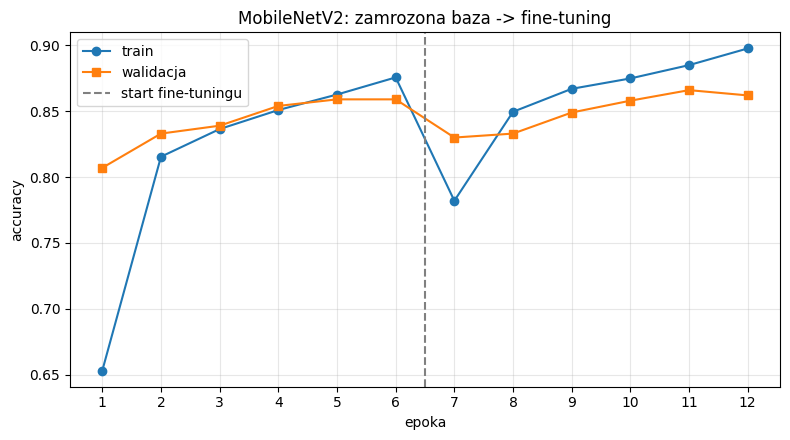

In [22]:
EPOKI_TL2 = 1 if SZYBKI_TRYB else 6
N_ODMROZ = 30

# 1. Odmrazamy cala baze, po czym z powrotem zamrazamy wszystko poza ostatnimi N_ODMROZ warstwami
baza.trainable = True
for warstwa in baza.layers[:-N_ODMROZ]:
    warstwa.trainable = False
odmrozone = [w.name for w in baza.layers[-N_ODMROZ:]]
print(f"odmrozonych warstw: {len(odmrozone)}, m.in. {odmrozone[-3:]}")

# 2. Zmiana atrybutu trainable obowiazuje dopiero po ponownym compile; lr = 1e-5 chroni wagi ImageNet
model_tl.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# 3. Nowa liczba parametrow trenowalnych
print(f"parametry trenowalne po odmrozeniu: "
      f"{sum(int(np.prod(w.shape)) for w in model_tl.trainable_weights):,}")

# 4. Kontynuacja treningu od epoki, na ktorej skonczyl sie etap 1
epoki_etapu1 = len(hist_tl1.history["loss"])
t0 = time.time()
hist_tl2 = model_tl.fit(ds_tl_tr, epochs=epoki_etapu1 + EPOKI_TL2, initial_epoch=epoki_etapu1,
                        validation_data=ds_tl_va, verbose=2)
print(f"czas etapu 2: {time.time() - t0:.0f} s")

acc_tl2 = model_tl.evaluate(ds_tl_te, verbose=0)[1]
print(f"test accuracy (fine-tuning): {acc_tl2:.4f} (po etapie 1: {acc_tl1:.4f})")

# 5. Polaczone krzywe z obu etapow; pionowa linia = poczatek fine-tuningu
acc = hist_tl1.history["accuracy"] + hist_tl2.history["accuracy"]
val_acc = hist_tl1.history["val_accuracy"] + hist_tl2.history["val_accuracy"]
epoki = np.arange(1, len(acc) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epoki, acc, "o-", label="train")
ax.plot(epoki, val_acc, "s-", label="walidacja")
ax.axvline(epoki_etapu1 + 0.5, color="gray", ls="--", label="start fine-tuningu")
ax.set_xticks(epoki)
ax.set_xlabel("epoka"); ax.set_ylabel("accuracy")
ax.set_title("MobileNetV2: zamrozona baza -> fine-tuning")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Zadanie 6.3 - Macierz pomyłek i zestawienie wszystkich modeli

1. Wyznacz predykcje `model_tl` na `ds_tl_te` i narysuj macierz pomyłek funkcją `rysuj_macierz_pomylek` (nazwy `NAZWY_CIFAR`).
2. Wypisz `classification_report` (precision, recall, F1 per klasa - szczegóły w W4/L5).
3. Wskaż dwie najczęściej mylone pary klas i zastanów się, dlaczego.
4. Zbuduj końcową tabelę wszystkich modeli z L4 na CIFAR-10: baseline, CNN BN+aug, mini-ResNet, MobileNetV2 zamrożona, MobileNetV2 fine-tuning (parametry, test accuracy, liczba obrazów treningowych).

**Kryteria sukcesu:** kompletna tabela i macierz; najczęściej mylone pary zidentyfikowane z interpretacją.

**Uwaga:** modele CIFAR były oceniane na innym (większym) zbiorze testowym niż model transferowy - zaznacz to w tabeli i w sprawozdaniu (uczciwe raportowanie wyników, W4).

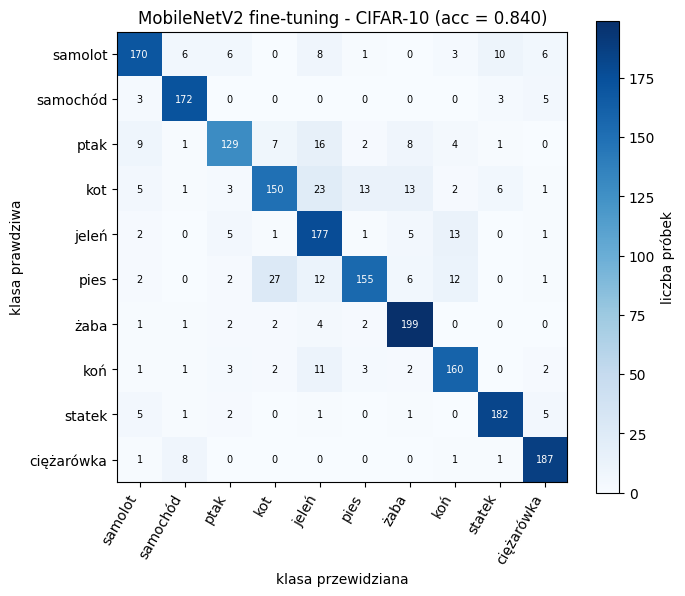

              precision    recall  f1-score   support

     samolot      0.854     0.810     0.831       210
    samochód      0.901     0.940     0.920       183
        ptak      0.849     0.729     0.784       177
         kot      0.794     0.691     0.739       217
       jeleń      0.702     0.863     0.775       205
        pies      0.876     0.714     0.787       217
        żaba      0.850     0.943     0.894       211
         koń      0.821     0.865     0.842       185
      statek      0.897     0.924     0.910       197
  ciężarówka      0.899     0.944     0.921       198

    accuracy                          0.841      2000
   macro avg      0.844     0.842     0.840      2000
weighted avg      0.843     0.841     0.839      2000

najczesciej mylone pary (prawda -> predykcja):
  pies       -> kot       : 27 razy
  kot        -> jeleń     : 23 razy
                        model  parametry  test accuracy  obrazy treningowe  test (n)
                 CNN baseline     356

In [23]:
# 1. Predykcje i macierz pomylek modelu transferowego
proby_tl = model_tl.predict(ds_tl_te, verbose=0)
y_pred_tl = proby_tl.argmax(axis=1)
cm_tl = rysuj_macierz_pomylek(y_tl_te, y_pred_tl, NAZWY_CIFAR,
                              f"MobileNetV2 fine-tuning - CIFAR-10 (acc = {acc_tl2:.3f})")

# 2. Precision, recall i F1 dla kazdej klasy
print(classification_report(y_tl_te, y_pred_tl, target_names=NAZWY_CIFAR,
                            digits=3, zero_division=0))

# 3. Dwie najczestsze pomylone pary (najwieksze wartosci poza przekatna)
m = cm_tl.copy()
np.fill_diagonal(m, 0)
print("najczesciej mylone pary (prawda -> predykcja):")
for _ in range(2):
    i, j = np.unravel_index(np.argmax(m), m.shape)
    print(f"  {NAZWY_CIFAR[i]:10s} -> {NAZWY_CIFAR[j]:10s}: {m[i, j]} razy")
    m[i, j] = 0

# 4. Tabela koncowa wszystkich modeli z L4; uwaga: inne zbiory testowe!
wyniki_cifar.append({"model": "MobileNetV2 zamrozona (6.1)", "parametry": model_tl.count_params(),
                     "test accuracy": acc_tl1, "obrazy treningowe": len(x_tl_tr),
                     "zbior testowy": len(x_tl_te)})
wyniki_cifar.append({"model": "MobileNetV2 fine-tuning (6.2)", "parametry": model_tl.count_params(),
                     "test accuracy": acc_tl2, "obrazy treningowe": len(x_tl_tr),
                     "zbior testowy": len(x_tl_te)})
tabela_koncowa = pd.DataFrame(wyniki_cifar).rename(columns={"zbior testowy": "test (n)"})
print(tabela_koncowa.round({"test accuracy": 4}).to_string(index=False))
print("\nParametry trenowalne MobileNetV2: etap 1 = 12 810, etap 2 (fine-tuning) =",
      f"{sum(int(np.prod(w.shape)) for w in model_tl.trainable_weights):,}")

## Pytania kontrolne

1. Obraz 64x64x3 przechodzi przez `Conv2D(20, kernel_size=5, strides=1, padding="valid")`. Jaki jest kształt wyjścia i ile parametrów ma warstwa?
2. Dlaczego warstwa splotowa ma znacznie mniej parametrów niż warstwa gęsta o porównywalnej liczbie wyjść? Wymień dwie własności splotu, które o tym decydują.
3. Co robi `MaxPooling2D(2)` i ile ma parametrów? Czym różni się od `GlobalAveragePooling2D`?
4. Dlaczego warstwy augmentacji w modelu nie zmieniają obrazów podczas `evaluate` i `predict`? Podaj przykład augmentacji, która byłaby **błędem** dla CIFAR-10, i przykład błędnej augmentacji dla MNIST.
5. Zapisz wzór bloku residualnego. Dlaczego połączenia residualne ułatwiają trenowanie głębokich sieci? Kiedy skrót wymaga splotu 1x1?
6. Opisz dwa etapy transfer learningu. Dlaczego w fine-tuningu stosujemy bardzo mały learning rate i dlaczego najpierw trenujemy samą głowę?
7. Co się stanie, jeśli obrazy podzielimy przez 255, a potem podamy do `mobilenet_v2.preprocess_input`?
8. Po co wywołujemy `baza(x, training=False)`, skoro i tak ustawiamy `baza.trainable`?

## Podsumowanie - co warto zapamiętać

- **Splot** = przesuwany filtr liczący iloczyn skalarny z fragmentem obrazu; w DL to formalnie korelacja. Wymiar wyjścia: $\lfloor (n + 2p - k)/s \rfloor + 1$; parametry: $k^2 C_{in} F + F$.
- Filtry (np. Sobela) wykrywają krawędzie; CNN **uczy się** filtrów z danych - płytkie warstwy: krawędzie i kolory, głębokie: abstrakcyjne wzorce o dużym polu recepcyjnym.
- **CNN > MLP** na obrazach dzięki lokalności i współdzieleniu wag; najwięcej parametrów często ma klasyfikator gęsty po `Flatten` - **GAP** to rozwiązuje.
- **BatchNorm + Dropout + augmentacja** (warstwy Keras w modelu, aktywne tylko w treningu) znacząco zmniejszają przeuczenie na CIFAR-10.
- **Blok residualny** $y = \text{ReLU}(F(x) + x)$, projekcja 1x1 przy zmianie wymiarów - podstawa ResNet i wielu nowoczesnych architektur.
- **Functional API** umożliwia rozgałęzienia (skróty) i wyciąganie map cech z warstw pośrednich.
- **Transfer learning:** zamrożona baza + nowa głowa (szybko, mało danych), potem fine-tuning górnych warstw z lr ok. 1e-5 i ponownym `compile`. Zawsze właściwy `preprocess_input` i `training=False` dla bazy z BN.
- Raportując wyniki, porównuj modele na **tym samym** zbiorze testowym albo wyraźnie zaznacz różnice.

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, maks. 2 strony):

1. **Tabelę MLP vs CNN** na Fashion-MNIST (zad. 2.1) z hipotezą i jej weryfikacją (UGŁ_U01).
2. **Krzywe uczenia** baseline'u CNN i modelu z zad. 3.1 na CIFAR-10 z komentarzem o wpływie augmentacji i BN na przeuczenie.
3. **Tabelę końcową** z zad. 6.3 (wszystkie modele CIFAR-10) z uwagą o różnych zbiorach testowych.
4. **Macierz pomyłek** modelu transferowego i interpretację najczęstszych pomyłek.
5. Jeden **wykres map cech** (zad. 5.1) z dwuzdaniową interpretacją.
6. **Propozycję usprawnienia** (UGŁ_U02), np. większa rozdzielczość wejścia (128/160), inny model z `keras.applications` (EfficientNetB0, ResNet50), więcej odmrożonych warstw, silniejsza augmentacja - z uzasadnieniem i, jeśli zdążysz, wynikiem eksperymentu.

## Zadanie dodatkowe (dla chętnych) - Grad-CAM

**Grad-CAM** (Selvaraju i in., 2017; W4 - interpretowalność) pokazuje, **które obszary obrazu** zadecydowały o przewidzianej klasie:

1. Dla obrazu $x$ i klasy $c$ liczymy mapy cech $A^k$ ostatniej warstwy splotowej oraz gradient wyniku klasy $y^c$ względem nich.
2. Wagi kanałów: $\alpha_k = \frac{1}{HW}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$ (średni gradient).
3. Mapa: $L^c = \text{ReLU}\left(\sum_k \alpha_k A^k\right)$, przeskalowana do rozmiaru obrazu i nałożona na niego.

Zaimplementuj funkcję `grad_cam(model, obraz, nazwa_warstwy)` dla `model_cifar` (warstwa `"ostatni_conv"`) używając `tf.GradientTape`, i pokaż mapy dla 6 obrazów testowych (obraz, mapa, nałożenie) z podpisem prawdziwej i przewidzianej klasy.

**Wskazówki:** model pomocniczy `keras.Model(model.inputs, [model.get_layer(nazwa).output, model.output])`; w `GradientTape` wywołaj go z `training=False`; `tf.image.resize` do 32x32.

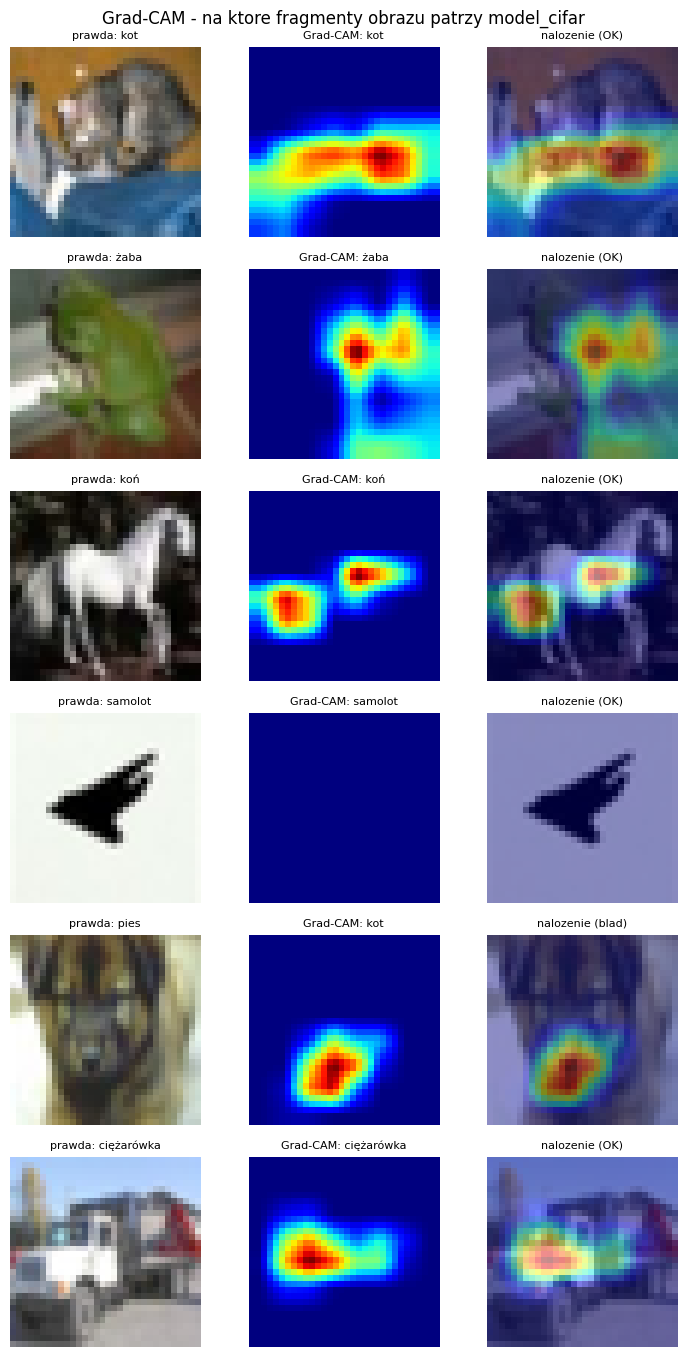

In [24]:
def grad_cam(model, obraz, nazwa_warstwy="ostatni_conv", klasa=None):
    # Grad-CAM: wazona suma map cech ostatniej warstwy splotowej, wagi = sredni gradient
    model_gc = keras.Model(model.input, [model.get_layer(nazwa_warstwy).output, model.output])
    with tf.GradientTape() as tape:
        mapy, pred = model_gc(obraz, training=False)      # (1, H, W, C), (1, 10)
        if klasa is None:
            klasa = int(tf.argmax(pred[0]))               # klasa przewidziana
        wynik = pred[:, klasa]
    gradienty = tape.gradient(wynik, mapy)                # (1, H, W, C)
    alfa = tf.reduce_mean(gradienty, axis=(1, 2))         # sredni gradient per kanal (1, C)
    mapa = tf.reduce_sum(mapy * alfa[:, None, None, :], axis=-1)   # suma po kanalach
    mapa = tf.nn.relu(mapa)                               # tylko cechy wspierajace klase
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)            # normalizacja do [0, 1]
    mapa = tf.image.resize(mapa[..., None], (obraz.shape[1], obraz.shape[2]))[0, :, :, 0]
    return mapa.numpy(), int(klasa)


indeksy = [0, 7, 13, 21, 33, 45]                          # 6 obrazow testowych
fig, axes = plt.subplots(len(indeksy), 3, figsize=(7.5, 2.3 * len(indeksy)))
for w, idx in enumerate(indeksy):
    obraz = xc_te[idx:idx + 1]
    mapa, klasa = grad_cam(model_cifar, obraz, "ostatni_conv")
    prawda = int(yc_test[idx])
    for ax in axes[w]:
        ax.axis("off")
    axes[w, 0].imshow(obraz[0])
    axes[w, 0].set_title(f"prawda: {NAZWY_CIFAR[prawda]}", fontsize=8)
    axes[w, 1].imshow(mapa, cmap="jet")
    axes[w, 1].set_title(f"Grad-CAM: {NAZWY_CIFAR[klasa]}", fontsize=8)
    axes[w, 2].imshow(obraz[0]); axes[w, 2].imshow(mapa, cmap="jet", alpha=0.45)
    axes[w, 2].set_title("nalozenie " + ("(OK)" if klasa == prawda else "(blad)"), fontsize=8)
plt.suptitle("Grad-CAM - na ktore fragmenty obrazu patrzy model_cifar")
plt.tight_layout(); plt.show()